# Klasifikasi Penutup Lahan Jawa Timur Berbasis Sentinel-2 dan Perbandingan Algoritma Machine Learning

**UTS Sistem Informasi Geografis — Analisis Spasial Penggunaan Lahan dan Kebijakan**

Magdalena Jovita Hatuopar (NIM 240411100078) · Teknik Informatika, Universitas Trunodjoyo Madura

Aplikasi Streamlit: https://lulc-jatim-njdu8ic5w8zcxph8yhzqfh.streamlit.app/

**Alur:** poligon GeoJSON (6 kelas) → titik sampel (split per poligon) → Google Earth Engine (Sentinel-2A L2A, komposit median 2025) → 20 fitur → EDA → 8 algoritma → model terbaik → prediksi ROI → peta Folium (Google Satellite) → Streamlit + web statis.

## Daftar Isi
1. Data Understanding · 2. Data Collection · 3. Deskripsi Fitur dan Rumus · 4. EDA · 5. Model Dasar (Random Forest) · 6. Eksperimen · 7. Peta Klasifikasi · 8. Streamlit dan Web Statis · 9. Kesimpulan dan Keterbatasan

## Pemenuhan ketentuan tugas
| Ketentuan tugas | Letak di notebook |
|---|---|
| Tujuan analisis LULC | 1.1 – 1.3 |
| Kolekting data (sumber, periode, pra-pemrosesan) | 2.1, 2.4 |
| Deskripsi band Sentinel-2A | 1.5 |
| Jumlah data latih, uji, dan kelas | 2.3 |
| Deskripsi fitur dan rumus | Bagian 3 |
| Klasifikasi lahan Indonesia (KLHK dan SNI 7645) | 1.4 |
| 6 kelas: sawah, bangunan, mangrove, lahan hijau, laut, danau (ranu) | 1.4, 2.2 |
| Perbandingan model dan pemilihan akurasi tertinggi | 6.4, 6.5 |
| Hasil pada peta Google Satellite (Folium/Leaflet) | 7.2 |
| Deploy Streamlit | Bagian 8 |
| Proses dalam web statis | 8.3 |

## 0. Persiapan

In [1]:
# %pip install -q geopandas folium xgboost lightgbm seaborn scikit-learn   # jalankan di Colab bila perlu
import json, time, warnings, base64
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.image as mpimg, seaborn as sns
import geopandas as gpd, folium
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50, "display.width", 170)

# Cari folder data (sesuaikan bila perlu)
for cand in ["data", "data - Copy", "."]:
    if (Path(cand) / "dataset_fitur.csv").exists():
        DATA = Path(cand); break
else:
    raise FileNotFoundError("Taruh dataset_fitur.csv dkk. di folder 'data/' di samping notebook ini.")
print("Folder data:", DATA.resolve())
SEED = 42
JALANKAN_ULANG_MODEL = True    # False = hanya baca model_results.csv, tanpa melatih ulang 8 model

CLASSES = [{'id': 1, 'name': 'Sawah', 'color': '#FFD500', 'klhk': 'Sawah (20093)', 'sni': 'Pertanian - sawah (daerah bervegetasi)', 'desc': 'Lahan pertanian yang digenangi/diairi secara periodik untuk padi.'}, {'id': 2, 'name': 'Bangunan', 'color': '#E31A1C', 'klhk': 'Permukiman (2012)', 'sni': 'Permukiman & lahan bukan pertanian (tak bervegetasi)', 'desc': 'Area terbangun: permukiman, industri, jalan, fasilitas umum.'}, {'id': 3, 'name': 'Mangrove', 'color': '#006D2C', 'klhk': 'Hutan mangrove primer/sekunder (2004/2005)', 'sni': 'Hutan - mangrove (daerah bervegetasi)', 'desc': 'Vegetasi hutan pasang-surut di pesisir (Surabaya, Sidoarjo, Probolinggo, Banyuwangi, dll).'}, {'id': 4, 'name': 'Lahan Hijau', 'color': '#74C476', 'klhk': 'Hutan lahan kering / perkebunan / pertanian lahan kering (2001/2002/2010/20091)', 'sni': 'Hutan, perkebunan, pertanian lahan kering (daerah bervegetasi)', 'desc': 'Vegetasi non-sawah dan non-mangrove: hutan, kebun, tegalan, semak.'}, {'id': 5, 'name': 'Perairan Terbuka (Laut)', 'color': '#08306B', 'klhk': 'Tubuh air (5001)', 'sni': 'Perairan (daerah tak bervegetasi)', 'desc': 'Laut/selat terbuka (Laut Jawa, Selat Madura, Selat Bali, Samudra Hindia).'}, {'id': 6, 'name': 'Danau (Ranu)', 'color': '#41B6E6', 'klhk': 'Tubuh air (5001)', 'sni': 'Perairan (daerah tak bervegetasi)', 'desc': 'Danau/ranu/waduk daratan (mis. Ranu Klakah, Ranu Bedali, Ranu Pani, Ranu Grati).'}]
INDEX = [{'name': 'NDVI', 'formula': '(B8 - B4) / (B8 + B4)', 'latex': 'NDVI=\\frac{B8-B4}{B8+B4}', 'fungsi': 'Kehijauan/kerapatan vegetasi'}, {'name': 'NDWI', 'formula': '(B3 - B8) / (B3 + B8)', 'latex': 'NDWI=\\frac{B3-B8}{B3+B8}', 'fungsi': 'Badan air terbuka (McFeeters)'}, {'name': 'MNDWI', 'formula': '(B3 - B11) / (B3 + B11)', 'latex': 'MNDWI=\\frac{B3-B11}{B3+B11}', 'fungsi': 'Air, menekan noise bangunan (Xu)'}, {'name': 'NDBI', 'formula': '(B11 - B8) / (B11 + B8)', 'latex': 'NDBI=\\frac{B11-B8}{B11+B8}', 'fungsi': 'Area terbangun'}, {'name': 'NDMI', 'formula': '(B8 - B11) / (B8 + B11)', 'latex': 'NDMI=\\frac{B8-B11}{B8+B11}', 'fungsi': 'Kadar air vegetasi (sawah/mangrove)'}, {'name': 'EVI', 'formula': '2.5 * (B8 - B4) / (B8 + 6*B4 - 7.5*B2 + 1)', 'latex': 'EVI=2.5\\times\\frac{B8-B4}{B8+6\\cdot B4-7.5\\cdot B2+1}', 'fungsi': 'Vegetasi dengan koreksi atmosfer & saturasi'}, {'name': 'SAVI', 'formula': '1.5 * (B8 - B4) / (B8 + B4 + 0.5)', 'latex': 'SAVI=\\frac{B8-B4}{B8+B4+L}\\times(1+L),\\ L=0.5', 'fungsi': 'Vegetasi dengan koreksi pengaruh tanah'}, {'name': 'CMRI', 'formula': 'NDVI - NDWI', 'latex': 'CMRI=NDVI-NDWI', 'fungsi': 'Combined Mangrove Recognition Index (membantu mangrove)'}]
TOPO = [{'name': 'elevation', 'formula': 'SRTM GL1 (USGS/SRTMGL1_003), 30 m', 'fungsi': 'Ketinggian (m dpl): danau/ranu di dataran tinggi, mangrove ~0 m'}, {'name': 'slope', 'formula': 'ee.Terrain.slope(elevation)', 'fungsi': 'Kemiringan lereng (derajat): sawah datar, lahan hijau bisa curam'}]
BANDS = [['B1', 'Coastal aerosol', 442.7, 21, 60, False, 'Koreksi aerosol & studi pesisir'], ['B2', 'Blue', 492.4, 66, 10, True, 'Pembeda air/tanah, komponen EVI'], ['B3', 'Green', 559.8, 36, 10, True, 'Puncak pantulan vegetasi, NDWI/MNDWI'], ['B4', 'Red', 664.6, 31, 10, True, 'Serapan klorofil, NDVI'], ['B5', 'Vegetation Red Edge 1', 704.1, 15, 20, True, 'Kondisi klorofil vegetasi'], ['B6', 'Vegetation Red Edge 2', 740.5, 15, 20, True, 'Struktur kanopi'], ['B7', 'Vegetation Red Edge 3', 782.8, 20, 20, True, 'Struktur kanopi'], ['B8', 'NIR', 832.8, 106, 10, True, 'Biomassa vegetasi, batas air-darat'], ['B8A', 'Narrow NIR', 864.7, 21, 20, True, 'Vegetasi (NIR sempit)'], ['B9', 'Water vapour', 945.1, 20, 60, False, 'Uap air atmosfer'], ['B10', 'SWIR - Cirrus', 1373.5, 31, 60, False, 'Deteksi awan cirrus (tidak ada di produk L2A)'], ['B11', 'SWIR 1', 1613.7, 91, 20, True, 'Kadar air vegetasi/tanah, area terbangun'], ['B12', 'SWIR 2', 2202.4, 175, 20, True, 'Kadar air, tanah terbuka, bangunan']]
NAMES = [c["name"] for c in CLASSES]
COLORS = {c["name"]: c["color"] for c in CLASSES}
S2_BANDS = ["B2","B3","B4","B5","B6","B7","B8","B8A","B11","B12"]
IDX_NAMES = [i["name"] for i in INDEX]
FEATURES = S2_BANDS + IDX_NAMES + ["elevation", "slope"]
print(len(FEATURES), "fitur:", FEATURES)

Folder data: /home/claude/nbrun/data
20 fitur: ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'MNDWI', 'NDBI', 'NDMI', 'EVI', 'SAVI', 'CMRI', 'elevation', 'slope']


## 1. Data Understanding

### 1.1 Latar belakang
Jawa Timur adalah lumbung pangan nasional sekaligus provinsi dengan alih fungsi lahan yang cepat: sawah menjadi permukiman, mangrove pesisir menyusut, dan ranu/danau mengalami tekanan. Pemetaan penutup lahan dari citra satelit secara berkala menjadi dasar penataan ruang (RTRW) dan perlindungan lahan pertanian pangan berkelanjutan.

### 1.2 Tujuan analisis
1. Memetakan **6 kelas lahan**: sawah, bangunan, mangrove, lahan hijau, perairan terbuka (laut), danau (ranu).
2. Menganalisis karakter spektral setiap kelas.
3. Membandingkan **8 algoritma** dan memakai yang akurasinya tertinggi.
4. Menampilkan hasil pada peta satelit interaktif (Folium/Leaflet + Google Satellite).
5. Menurunkan implikasi kebijakan dan membangun sistem informasi (Streamlit + web statis).

### 1.3 Wilayah studi
Provinsi Jawa Timur. Prediksi peta dilakukan pada 4 area (ROI) yang mewakili keenam kelas: Surabaya–Gresik–Sidoarjo (pesisir), Mojokerto–Jombang (sawah), Lumajang (Ranu Klakah/Bedali), dan Malang Selatan.

### 1.4 Kelas dan padanannya terhadap klasifikasi resmi Indonesia
Klasifikasi tidak hanya sawah vs non-sawah. Acuannya **KLHK** (klasifikasi penutupan lahan nasional, ±23 kelas) dan **SNI 7645:2010** (revisi SNI 7645-1:2014: daerah bervegetasi dan tak bervegetasi).

In [2]:
display(pd.DataFrame([{"ID": c["id"], "Kelas": c["name"], "Padanan KLHK": c["klhk"], "Padanan SNI": c["sni"],
                       "Deskripsi": c["desc"]} for c in CLASSES]))

,ID,Kelas,Padanan KLHK,Padanan SNI,Deskripsi
0,1,Sawah,Sawah (20093),Pertanian - sawah (daerah bervegetasi),Lahan pertanian yang digenangi/diairi secara p...
1,2,Bangunan,Permukiman (2012),Permukiman & lahan bukan pertanian (tak berveg...,"Area terbangun: permukiman, industri, jalan, f..."
2,3,Mangrove,Hutan mangrove primer/sekunder (2004/2005),Hutan - mangrove (daerah bervegetasi),Vegetasi hutan pasang-surut di pesisir (Suraba...
3,4,Lahan Hijau,Hutan lahan kering / perkebunan / pertanian la...,"Hutan, perkebunan, pertanian lahan kering (dae...","Vegetasi non-sawah dan non-mangrove: hutan, ke..."
4,5,Perairan Terbuka (Laut),Tubuh air (5001),Perairan (daerah tak bervegetasi),"Laut/selat terbuka (Laut Jawa, Selat Madura, S..."
5,6,Danau (Ranu),Tubuh air (5001),Perairan (daerah tak bervegetasi),"Danau/ranu/waduk daratan (mis. Ranu Klakah, Ra..."


### 1.5 Band Sentinel-2A (MSI)

In [3]:
band_df = pd.DataFrame(BANDS, columns=["Band","Nama","λ tengah (nm)","Lebar (nm)","Resolusi (m)","Dipakai","Kegunaan"])
band_df["Dipakai"] = band_df["Dipakai"].map({True: "Ya", False: "Tidak"})
display(band_df)
print("B1, B9, B10 (60 m: aerosol, uap air, cirrus) tidak dipakai sebagai fitur.")

,Band,Nama,λ tengah (nm),Lebar (nm),Resolusi (m),Dipakai,Kegunaan
0,B1,Coastal aerosol,442.7,21,60,Tidak,Koreksi aerosol & studi pesisir
1,B2,Blue,492.4,66,10,Ya,"Pembeda air/tanah, komponen EVI"
2,B3,Green,559.8,36,10,Ya,"Puncak pantulan vegetasi, NDWI/MNDWI"
3,B4,Red,664.6,31,10,Ya,"Serapan klorofil, NDVI"
4,B5,Vegetation Red Edge 1,704.1,15,20,Ya,Kondisi klorofil vegetasi
5,B6,Vegetation Red Edge 2,740.5,15,20,Ya,Struktur kanopi
6,B7,Vegetation Red Edge 3,782.8,20,20,Ya,Struktur kanopi
7,B8,NIR,832.8,106,10,Ya,"Biomassa vegetasi, batas air-darat"
8,B8A,Narrow NIR,864.7,21,20,Ya,Vegetasi (NIR sempit)
9,B9,Water vapour,945.1,20,60,Tidak,Uap air atmosfer


B1, B9, B10 (60 m: aerosol, uap air, cirrus) tidak dipakai sebagai fitur.


### 1.6 Alur kerja
`GeoJSON 6 kelas` → `poligon sampel (ID per poligon)` → `split latih/uji per poligon` → `titik sampel` → `GEE: komposit median Sentinel-2A 2025 + SRTM` → `20 fitur` → `EDA` → `8 algoritma` → `model terbaik` → `prediksi raster ROI` → `peta Folium` → `Streamlit / web statis`.

## 2. Data Collection

### 2.1 Parameter
| Parameter | Nilai |
|---|---|
| Koleksi citra | `COPERNICUS/S2_SR_HARMONIZED` (Sentinel-2 Level-2A, reflektansi permukaan) |
| Periode | 2025-01-01 s.d. 2025-12-31 |
| Filter awan | `CLOUDY_PIXEL_PERCENTAGE` < 30% |
| Pra-pemrosesan | Masker awan/bayangan/cirrus/salju dengan band SCL, komposit **median**, skala 1/10.000 |
| Topografi | SRTM GL1 30 m (elevasi dan slope) |
| Resolusi dan CRS | 10 m, EPSG:32749 (UTM 49S) |
| Platform | Google Earth Engine |

### 2.2 Membaca poligon digitasi (6 GeoJSON)

In [4]:
RAW = DATA / "raw"
files = {"Sawah": "sawah_Jawa_Timur.geojson", "Bangunan": "bangunan.geojson", "Mangrove": "Mangrove.geojson",
         "Lahan Hijau": "Lahan_ijo2.geojson", "Perairan Terbuka (Laut)": "laut.geojson", "Danau (Ranu)": "Danau.geojson"}
rows = []
for k, f in files.items():
    g = gpd.read_file(RAW / f).to_crs(4326)
    rows.append({"Kelas": k, "File": f, "Jumlah poligon": len(g),
                 "Luas total (ha)": round(g.to_crs(32749).area.sum() / 1e4, 1)})
display(pd.DataFrame(rows))

,Kelas,File,Jumlah poligon,Luas total (ha)
0,Sawah,sawah_Jawa_Timur.geojson,60,18514.6
1,Bangunan,bangunan.geojson,60,2867.1
2,Mangrove,Mangrove.geojson,60,1608.1
3,Lahan Hijau,Lahan_ijo2.geojson,60,52699.9
4,Perairan Terbuka (Laut),laut.geojson,60,121780.8
5,Danau (Ranu),Danau.geojson,60,2436.7


### 2.3 Pemilihan titik sampel
Poligon digabung dan diberi ID (`poly_id`). Pembagian latih/uji dilakukan **per poligon**, bukan per piksel: titik dari satu poligon hanya masuk ke latih **atau** uji. Cara ini mencegah kebocoran spasial, karena piksel bertetangga hampir identik secara spektral sehingga split acak akan membuat akurasi uji tampak terlalu tinggi.

In [5]:
df = pd.read_csv(DATA / "dataset_fitur.csv")
print("Bentuk data:", df.shape, "| nilai kosong:", int(df[FEATURES].isna().sum().sum()))
tab = df.pivot_table(index="class_name", columns="split", values="pid", aggfunc="count", margins=True).loc[NAMES + ["All"]]
display(tab)
tr, te = df[df.split == "train"], df[df.split == "test"]
Xtr, ytr, Xte, yte = tr[FEATURES], tr.class_id, te[FEATURES], te.class_id
print(f"Latih {len(tr)} | Uji {len(te)} | kelas {df.class_id.nunique()} | fitur {len(FEATURES)}")
print("Poligon yang muncul di latih dan uji sekaligus (harus 0):", len(set(tr.poly_id) & set(te.poly_id)))
display(df.groupby("class_name").poly_id.nunique().rename("Jumlah poligon").loc[NAMES].to_frame())

Bentuk data: (5996, 27) | nilai kosong: 0


split,test,train,All
class_name,,,
Sawah,303,697,1000
Bangunan,276,721,997
Mangrove,284,715,999
Lahan Hijau,311,691,1002
Perairan Terbuka (Laut),302,697,999
Danau (Ranu),390,609,999
All,1866,4130,5996


Latih 4130 | Uji 1866 | kelas 6 | fitur 20
Poligon yang muncul di latih dan uji sekaligus (harus 0): 0


,Jumlah poligon
class_name,
Sawah,60
Bangunan,58
Mangrove,60
Lahan Hijau,60
Perairan Terbuka (Laut),61
Danau (Ranu),59


#### 2.3.1 Sebaran poligon sampel (Google Satellite)

In [6]:
SAT = "https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}"
m = folium.Map(location=[-7.75, 112.6], zoom_start=8, tiles=None, control_scale=True)
folium.TileLayer(SAT, name="Google Satellite", attr="Google", max_zoom=20).add_to(m)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(m)
sg = json.loads((DATA / "samples_all.geojson").read_text())
for c in CLASSES:
    feats = [f for f in sg["features"] if f["properties"]["class_id"] == c["id"]]
    fg = folium.FeatureGroup(name=f'{c["id"]}. {c["name"]}')
    folium.GeoJson({"type": "FeatureCollection", "features": feats},
                   style_function=lambda _f, col=c["color"]: dict(color=col, weight=2, fillColor=col, fillOpacity=0.4),
                   tooltip=folium.GeoJsonTooltip(fields=["poly_id", "split", "luas_ha"], aliases=["ID", "Split", "Luas (ha)"])).add_to(fg)
    fg.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m

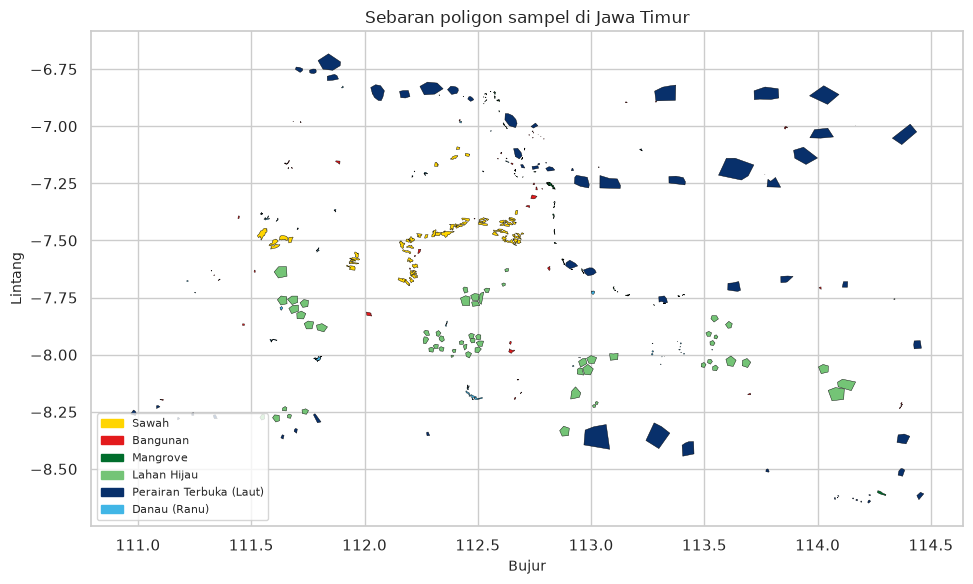

In [7]:
# Versi gambar statis (tetap terlihat di GitHub/PDF, tempat peta interaktif tidak tampil)
fig, ax = plt.subplots(figsize=(11, 6))
sgdf = gpd.GeoDataFrame.from_features(sg["features"], crs=4326)
for c in CLASSES:
    sgdf[sgdf.class_id == c["id"]].plot(ax=ax, color=c["color"], edgecolor="black", linewidth=0.3, label=c["name"])
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c["color"]) for c in CLASSES], labels=NAMES, loc="lower left", fontsize=8)
ax.set_title("Sebaran poligon sampel di Jawa Timur"); ax.set_xlabel("Bujur"); ax.set_ylabel("Lintang")
plt.tight_layout(); plt.show()

### 2.4 Pengambilan citra Sentinel-2A dan ekstraksi fitur (Google Earth Engine)

Ekstraksi dijalankan di Google Earth Engine; hasilnya adalah `dataset_fitur.csv` yang dibaca di atas. Ringkasan logikanya:
```python
s2 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(jatim)
      .filterDate("2025-01-01", "2025-12-31").filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 30))
      .map(mask_scl)                       # buang awan, bayangan, cirrus, salju (band SCL)
      .median().select(BANDS).divide(10000))
fitur = s2.addBands(indeks).addBands(srtm_elevasi).addBands(srtm_slope)   # 20 band
samples = fitur.sampleRegions(collection=titik, scale=10, geometries=False)
```

## 3. Deskripsi Fitur dan Rumus

Total **20 fitur** = 10 band + 8 indeks spektral + 2 topografi.

### 3.1 Fitur band asli (10)

In [8]:
display(band_df[band_df['Dipakai'] == 'Ya'].reset_index(drop=True))

,Band,Nama,λ tengah (nm),Lebar (nm),Resolusi (m),Dipakai,Kegunaan
0,B2,Blue,492.4,66,10,Ya,"Pembeda air/tanah, komponen EVI"
1,B3,Green,559.8,36,10,Ya,"Puncak pantulan vegetasi, NDWI/MNDWI"
2,B4,Red,664.6,31,10,Ya,"Serapan klorofil, NDVI"
3,B5,Vegetation Red Edge 1,704.1,15,20,Ya,Kondisi klorofil vegetasi
4,B6,Vegetation Red Edge 2,740.5,15,20,Ya,Struktur kanopi
5,B7,Vegetation Red Edge 3,782.8,20,20,Ya,Struktur kanopi
6,B8,NIR,832.8,106,10,Ya,"Biomassa vegetasi, batas air-darat"
7,B8A,Narrow NIR,864.7,21,20,Ya,Vegetasi (NIR sempit)
8,B11,SWIR 1,1613.7,91,20,Ya,"Kadar air vegetasi/tanah, area terbangun"
9,B12,SWIR 2,2202.4,175,20,Ya,"Kadar air, tanah terbuka, bangunan"


### 3.2 Fitur indeks spektral (8)

In [9]:
from IPython.display import Math
for i in INDEX:
    print(f"{i['name']}: {i['fungsi']}")
    display(Math(i["latex"]))

NDVI: Kehijauan/kerapatan vegetasi


<IPython.core.display.Math object>

NDWI: Badan air terbuka (McFeeters)


<IPython.core.display.Math object>

MNDWI: Air, menekan noise bangunan (Xu)


...

<IPython.core.display.Math object>

SAVI: Vegetasi dengan koreksi pengaruh tanah


<IPython.core.display.Math object>

CMRI: Combined Mangrove Recognition Index (membantu mangrove)


<IPython.core.display.Math object>

### 3.3 Fitur topografi (2)

In [10]:
display(pd.DataFrame(TOPO))

,name,formula,fungsi
0,elevation,"SRTM GL1 (USGS/SRTMGL1_003), 30 m",Ketinggian (m dpl): danau/ranu di dataran ting...
1,slope,ee.Terrain.slope(elevation),"Kemiringan lereng (derajat): sawah datar, laha..."


### 3.4 Fitur pada data sampel

In [11]:
display(df[FEATURES].head(5).round(4))

,B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12,NDVI,NDWI,MNDWI,NDBI,NDMI,EVI,SAVI,CMRI,elevation,slope
0,0.0463,0.0635,0.0505,0.0924,0.2120,0.2500,0.2393,0.2699,0.1411,0.0672,0.6514,-0.5808,-0.3798,-0.2579,0.2579,0.3949,0.3585,1.2322,66,2.6329
1,0.0341,0.0527,0.0347,0.0798,0.2051,0.2436,0.2323,0.2627,0.0967,0.0501,0.7404,-0.6305,-0.2952,-0.4119,0.4119,0.4172,0.3866,1.3709,11,1.8543
2,0.0612,0.0812,0.0469,0.0423,0.0179,0.0165,0.0128,0.0125,0.0082,0.0061,-0.5712,0.7277,0.8166,-0.2190,0.2190,-0.1021,-0.0914,-1.2988,0,0.0000
3,0.0657,0.0834,0.0629,0.1088,0.2335,0.2785,0.2731,0.2991,0.1716,0.0841,0.6256,-0.5321,-0.3459,-0.2282,0.2282,0.4538,0.3772,1.1577,49,2.9330
4,0.0514,0.0690,0.0658,0.1099,0.2096,0.2506,0.2373,0.2794,0.1428,0.0724,0.5657,-0.5494,-0.3484,-0.2485,0.2485,0.3438,0.3202,1.1151,60,1.8704


## 4. Exploratory Data Analysis (EDA)

### 4.1 Jumlah sampel per kelas

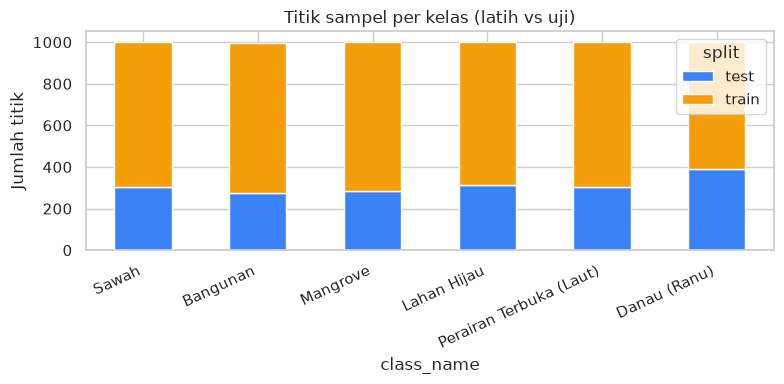

In [12]:
ct = df.groupby(["class_name", "split"]).size().unstack(fill_value=0).loc[NAMES]
ct.plot(kind="bar", stacked=True, figsize=(8, 4), color=["#3b82f6", "#f59e0b"])
plt.title("Titik sampel per kelas (latih vs uji)"); plt.ylabel("Jumlah titik"); plt.xticks(rotation=25, ha="right")
plt.tight_layout(); plt.show()

### 4.2 Statistik deskriptif

In [13]:
display(df[FEATURES].describe().T.round(4))
display(df.groupby("class_name")[FEATURES].mean().loc[NAMES].round(3))

,count,mean,std,min,25%,50%,75%,max
B2,5996.0,0.0527,0.0344,0.0083,0.0323,0.0426,0.0638,0.6260
B3,5996.0,0.0687,0.0347,0.0131,0.0483,0.0636,0.0792,0.6512
B4,5996.0,0.0523,0.0439,0.0060,0.0264,0.0358,0.0631,0.6488
B5,5996.0,0.0873,0.0496,0.0034,0.0403,0.0918,0.1153,0.5312
B6,5996.0,0.1624,0.1081,0.0000,0.0257,0.1945,0.2463,0.5769
B7,5996.0,0.1891,0.1302,0.0000,0.0263,0.2199,0.2959,0.7099
B8,5996.0,0.1872,0.1342,0.0000,0.0211,0.2156,0.2971,0.7824
B8A,5996.0,0.2019,0.1429,0.0000,0.0222,0.2357,0.3192,0.7357
B11,5996.0,0.1254,0.0950,0.0043,0.0172,0.1320,0.1865,0.6531
B12,5996.0,0.0797,0.0826,0.0034,0.0137,0.0562,0.0942,0.6977


,B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12,NDVI,NDWI,MNDWI,NDBI,NDMI,EVI,SAVI,CMRI,elevation,slope
class_name,,,,,,,,,,,,,,,,,,,,
Sawah,0.057,0.076,0.063,0.108,0.208,0.246,0.242,0.264,0.166,0.093,0.573,-0.512,-0.366,-0.185,0.185,0.372,0.329,1.085,32.956,1.730
Bangunan,0.097,0.113,0.126,0.157,0.196,0.213,0.208,0.226,0.267,0.236,0.253,-0.306,-0.420,0.129,-0.129,0.165,0.147,0.559,88.911,2.005
Mangrove,0.033,0.061,0.033,0.102,0.266,0.318,0.319,0.343,0.119,0.047,0.801,-0.671,-0.322,-0.453,0.453,0.559,0.499,1.472,2.705,1.409
Lahan Hijau,0.031,0.050,0.029,0.088,0.252,0.304,0.309,0.331,0.166,0.077,0.826,-0.719,-0.539,-0.295,0.295,0.555,0.494,1.545,1212.267,21.084
Perairan Terbuka (Laut),0.063,0.063,0.034,0.032,0.023,0.023,0.019,0.019,0.014,0.012,-0.253,0.503,0.595,-0.158,0.158,-0.054,-0.041,-0.756,0.005,0.007
Danau (Ranu),0.035,0.050,0.028,0.038,0.029,0.030,0.026,0.027,0.020,0.013,-0.268,0.488,0.501,-0.013,0.013,-0.011,-0.014,-0.756,317.877,3.254


### 4.3 Tanda spektral (spectral signature)

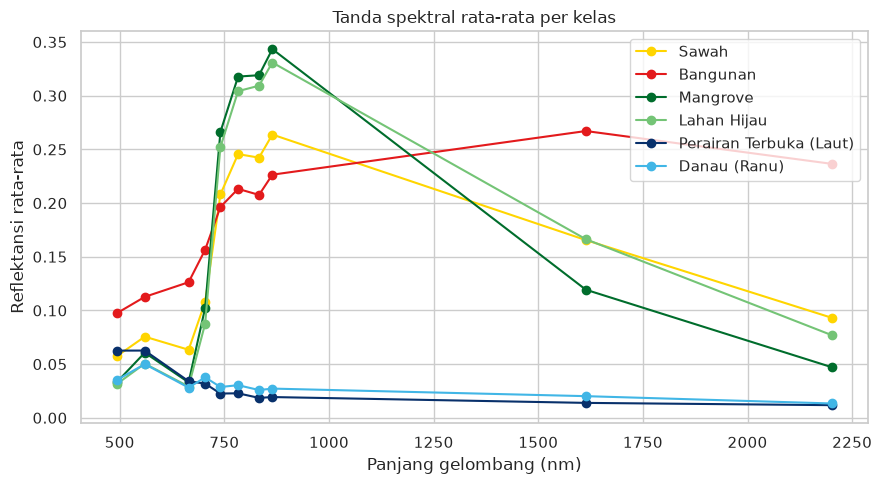

In [14]:
wl = {b[0]: b[2] for b in BANDS}
fig, ax = plt.subplots(figsize=(9, 5))
for n in NAMES:
    mu = df[df.class_name == n][S2_BANDS].mean()
    ax.plot([wl[b] for b in S2_BANDS], mu.values, marker="o", label=n, color=COLORS[n])
ax.set_xlabel("Panjang gelombang (nm)"); ax.set_ylabel("Reflektansi rata-rata")
ax.set_title("Tanda spektral rata-rata per kelas"); ax.legend(); plt.tight_layout(); plt.show()

### 4.4 Sebaran indeks per kelas

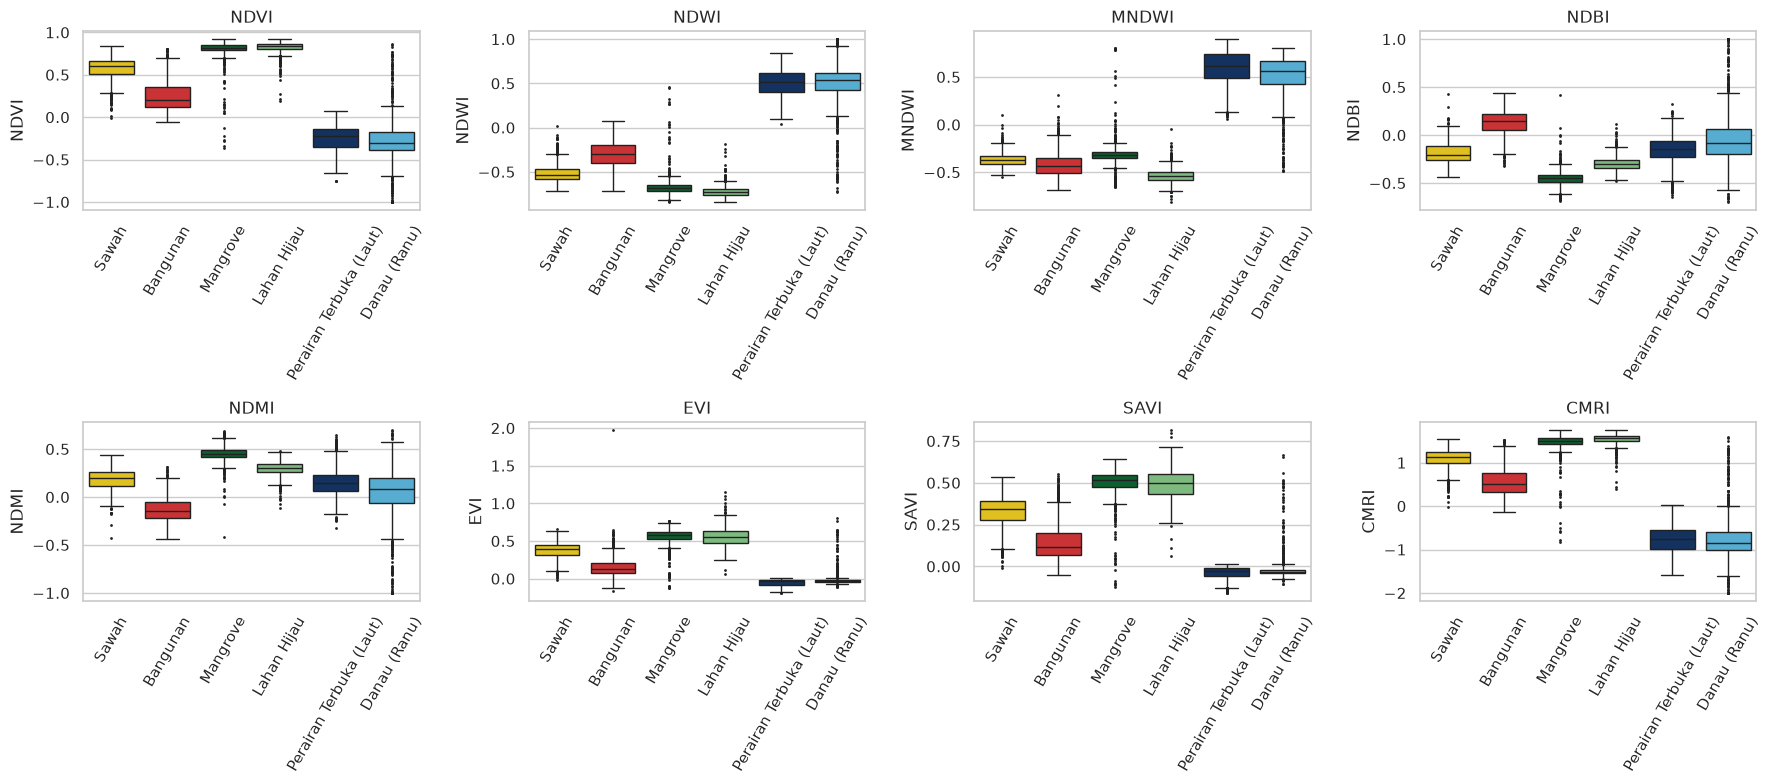

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, idx in zip(axes.ravel(), IDX_NAMES):
    sns.boxplot(data=df, x="class_name", y=idx, order=NAMES, palette=COLORS, ax=ax, fliersize=1)
    ax.set_title(idx); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

### 4.5 Topografi per kelas

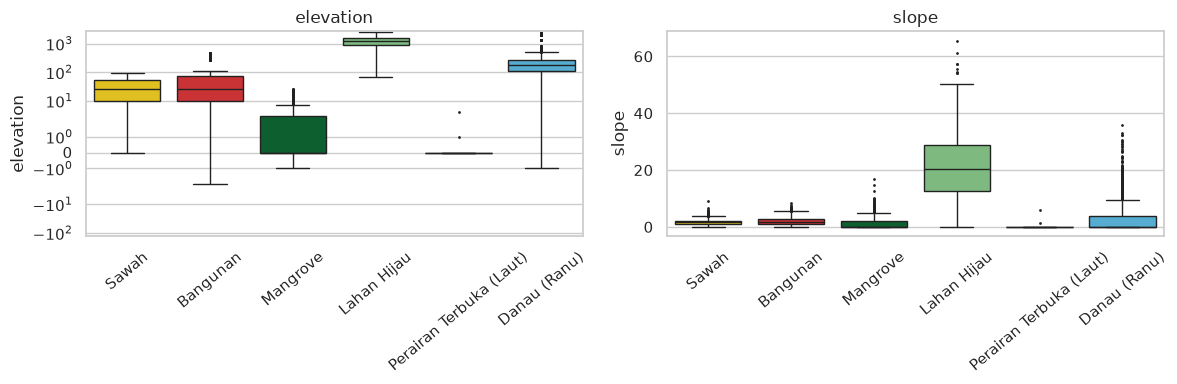

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, f in zip(axes, ["elevation", "slope"]):
    sns.boxplot(data=df, x="class_name", y=f, order=NAMES, palette=COLORS, ax=ax, fliersize=1)
    ax.set_title(f); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=40)
    if f == "elevation": ax.set_yscale("symlog")
plt.tight_layout(); plt.show()

### 4.6 Korelasi antar fitur

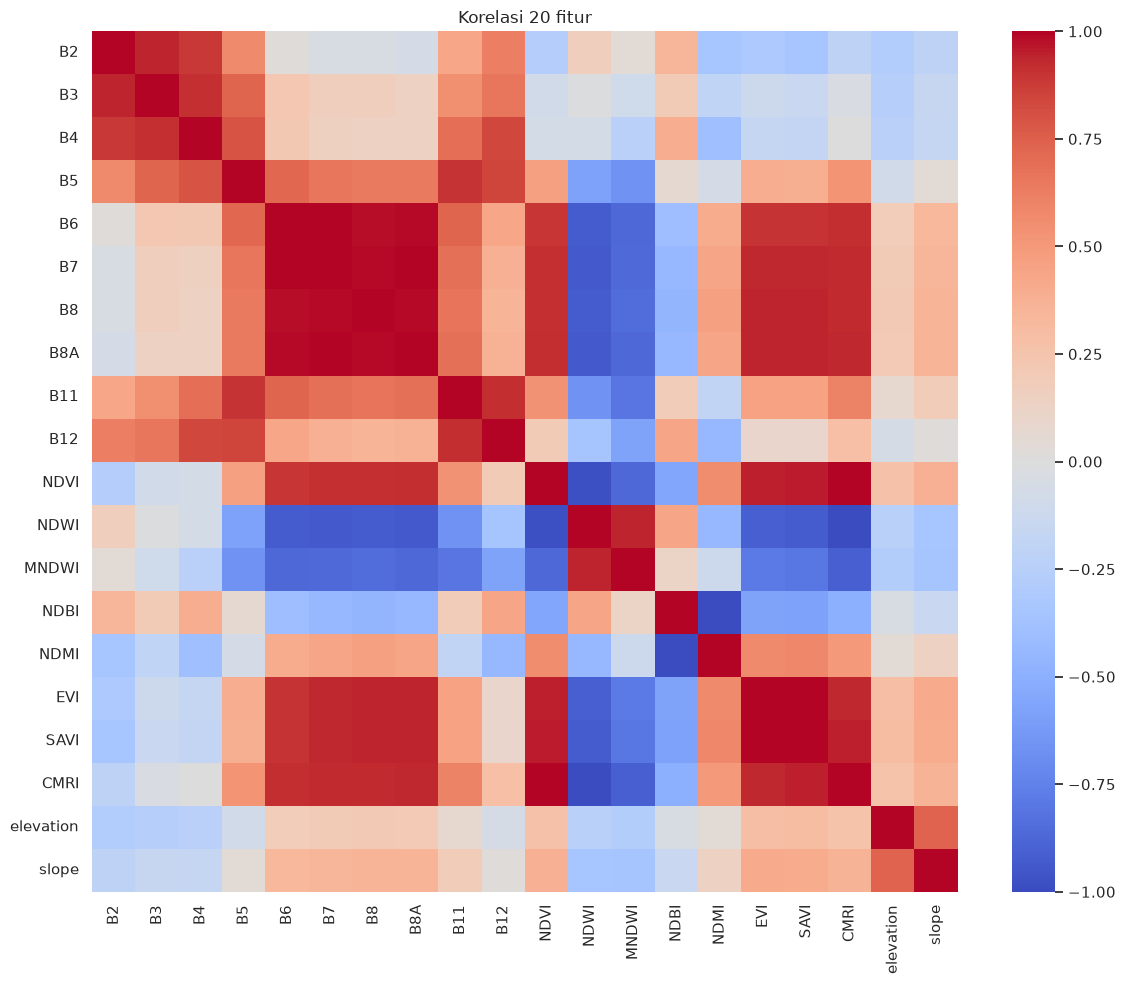

Pasangan fitur dengan |r| > 0.95 (redundan):


,Fitur A,Fitur B,|r|
0,B6,B7,0.994
1,B6,B8,0.984
2,B6,B8A,0.992
3,B7,B8,0.990
4,B7,B8A,0.998
5,B8,B8A,0.989
6,NDVI,NDWI,0.979
7,NDVI,SAVI,0.959
8,NDVI,CMRI,0.994
9,NDWI,CMRI,0.995


In [17]:
plt.figure(figsize=(12, 10))
sns.heatmap(df[FEATURES].corr(), cmap="coolwarm", center=0)
plt.title("Korelasi 20 fitur"); plt.tight_layout(); plt.show()
corr = df[FEATURES].corr().abs()
hi = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(FEATURES) for b in FEATURES[i+1:] if corr.loc[a, b] > 0.95]
print("Pasangan fitur dengan |r| > 0.95 (redundan):")
display(pd.DataFrame(hi, columns=["Fitur A", "Fitur B", "|r|"]))

**Pembacaan EDA.** Laut dan danau memiliki NDVI negatif; elevasi memisahkan keduanya (laut ≈ 0 m, danau/ranu ratusan meter). Mangrove dan lahan hijau sama-sama ber-NDVI tinggi, tetapi mangrove berada di ±0 m dan lahan hijau di dataran tinggi berlereng. Sawah dan bangunan berada di dataran rendah dan paling mudah tertukar. NDBI dan NDMI berkorelasi hampir sempurna secara negatif (keduanya memakai B8 dan B11), sehingga salah satunya redundan.

## 5. Model Dasar (Baseline): Random Forest

Random Forest dipakai sebagai baseline karena tidak sensitif terhadap skala fitur. Algoritma berbasis jarak/gradien (SVM, KNN, MLP) dibungkus `Pipeline(StandardScaler → model)` agar scaler hanya belajar dari data latih pada setiap fold.

Latih  akurasi=1.0000  kappa=1.0000  F1-macro=1.0000
Uji    akurasi=0.9641  kappa=0.9568  F1-macro=0.9630


                         precision    recall  f1-score   support

                  Sawah     0.9194    0.9406    0.9299       303
               Bangunan     0.9268    0.9638    0.9449       276
               Mangrove     0.9534    0.9366    0.9449       284
            Lahan Hijau     0.9967    0.9646    0.9804       311
Perairan Terbuka (Laut)     0.9967    1.0000    0.9983       302
           Danau (Ranu)     0.9845    0.9744    0.9794       390

               accuracy                         0.9641      1866
              macro avg     0.9629    0.9633    0.9630      1866
           weighted avg     0.9647    0.9641    0.9642      1866



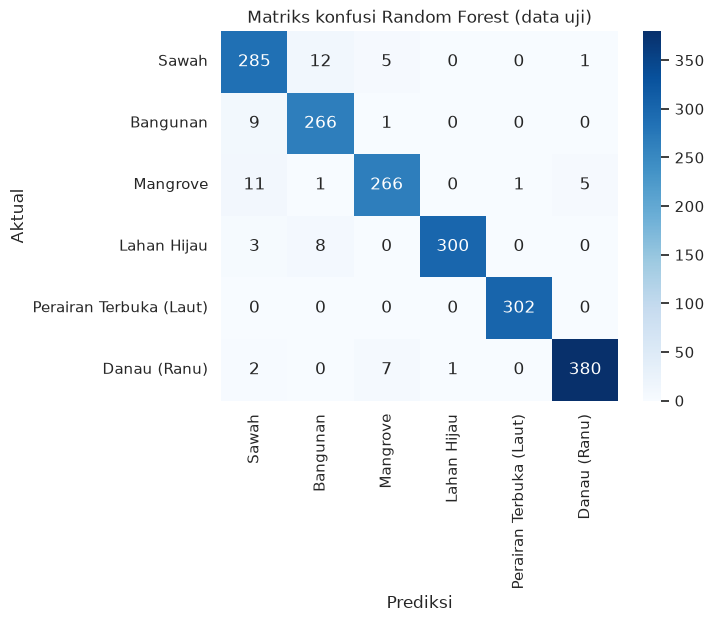

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score, classification_report, confusion_matrix
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(Xtr, ytr)
for nm, X, y in [("Latih", Xtr, ytr), ("Uji", Xte, yte)]:
    p = rf.predict(X)
    print(f"{nm:6s} akurasi={accuracy_score(y, p):.4f}  kappa={cohen_kappa_score(y, p):.4f}  F1-macro={f1_score(y, p, average='macro'):.4f}")
pte = rf.predict(Xte)
print(classification_report(yte, pte, target_names=NAMES, digits=4))
sns.heatmap(confusion_matrix(yte, pte), annot=True, fmt="d", cmap="Blues", xticklabels=NAMES, yticklabels=NAMES)
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.title("Matriks konfusi Random Forest (data uji)"); plt.show()

## 6. Eksperimen

Eksperimen 6.1–6.3 memakai `StratifiedGroupKFold(5)` dengan grup = `poly_id` pada **data latih saja**; data uji tidak dipakai untuk memilih konfigurasi.

In [19]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, GroupShuffleSplit
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
def cv_acc(model, cols):
    return cross_val_score(model, tr[cols], tr.class_id - 1, groups=tr.poly_id, cv=cv, scoring="accuracy", n_jobs=-1)

### 6.1 Rasio latih:uji (split per poligon)

In [20]:
rows = []
for ts in [0.1, 0.2, 0.3, 0.4]:
    accs = []
    for seed in range(5):
        a, b = next(GroupShuffleSplit(n_splits=1, test_size=ts, random_state=seed).split(df, df.class_id, df.poly_id))
        m_ = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=seed).fit(df.iloc[a][FEATURES], df.iloc[a].class_id)
        accs.append(accuracy_score(df.iloc[b].class_id, m_.predict(df.iloc[b][FEATURES])))
    rows.append({"Porsi uji": ts, "Akurasi rata-rata": np.mean(accs), "Std": np.std(accs)})
r61 = pd.DataFrame(rows); display(r61.round(4))

,Porsi uji,Akurasi rata-rata,Std
0,0.1,0.9789,0.0090
1,0.2,0.9756,0.0068
2,0.3,0.9715,0.0067
3,0.4,0.9650,0.0103


### 6.2 Kombinasi fitur

,Skenario,Jumlah fitur,Akurasi CV,Std
4,"20 fitur (+ elevasi, slope)",20,0.9521,0.0293
1,10 band,10,0.9132,0.0349
3,10 band + 8 indeks,18,0.9098,0.0332
2,8 indeks,8,0.8534,0.0284
0,"4 band (B2,B3,B4,B8)",4,0.8347,0.0365


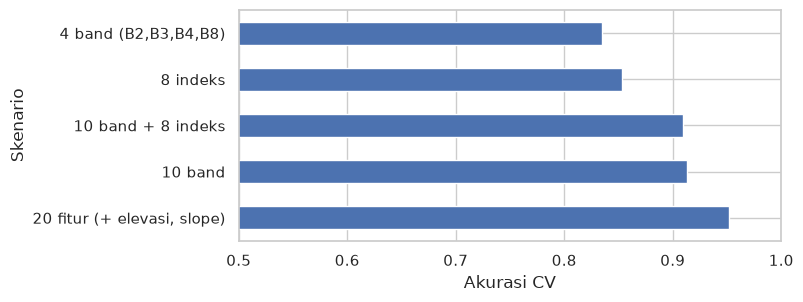

In [21]:
sets = {"4 band (B2,B3,B4,B8)": ["B2","B3","B4","B8"], "10 band": S2_BANDS, "8 indeks": IDX_NAMES,
        "10 band + 8 indeks": S2_BANDS + IDX_NAMES, "20 fitur (+ elevasi, slope)": FEATURES}
rows = []
for k, cols in sets.items():
    s = cv_acc(RandomForestClassifier(n_estimators=150, random_state=SEED), cols)
    rows.append({"Skenario": k, "Jumlah fitur": len(cols), "Akurasi CV": s.mean(), "Std": s.std()})
r62 = pd.DataFrame(rows).sort_values("Akurasi CV", ascending=False); display(r62.round(4))
r62.plot.barh(x="Skenario", y="Akurasi CV", legend=False, figsize=(7, 3)); plt.xlim(0.5, 1); plt.xlabel("Akurasi CV"); plt.show()

**Catatan 6.2.** Menambah elevasi dan slope menaikkan akurasi CV dari 0,910 (18 fitur spektral) menjadi 0,952. Fitur topografi paling besar kontribusinya, dan itu sekaligus sumber risiko generalisasi (lihat 7.3).

### 6.3 Hyperparameter XGBoost (model terbaik)

,max_depth,learning_rate,Akurasi CV,Std
2,3,0.20,0.9596,0.0260
1,3,0.10,0.9584,0.0274
7,9,0.10,0.9579,0.0286
8,9,0.20,0.9579,0.0281
6,9,0.05,0.9570,0.0283
5,6,0.20,0.9570,0.0296
4,6,0.10,0.9565,0.0301
3,6,0.05,0.9553,0.0292
0,3,0.05,0.9531,0.0297


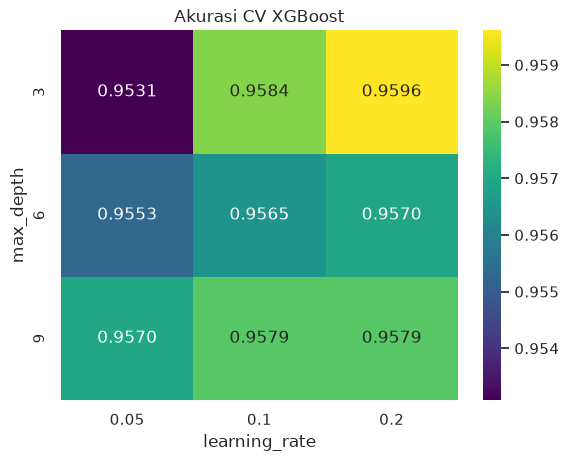

In [22]:
from xgboost import XGBClassifier
rows = []
for d in [3, 6, 9]:
    for lr in [0.05, 0.1, 0.2]:
        s = cv_acc(XGBClassifier(n_estimators=150, max_depth=d, learning_rate=lr, subsample=0.9, colsample_bytree=0.9,
                                 tree_method="hist", n_jobs=1, random_state=SEED, eval_metric="mlogloss"), FEATURES)
        rows.append({"max_depth": d, "learning_rate": lr, "Akurasi CV": s.mean(), "Std": s.std()})
r63 = pd.DataFrame(rows); display(r63.sort_values("Akurasi CV", ascending=False).round(4))
sns.heatmap(r63.pivot(index="max_depth", columns="learning_rate", values="Akurasi CV"), annot=True, fmt=".4f", cmap="viridis")
plt.title("Akurasi CV XGBoost"); plt.show()

### 6.4 Perbandingan 8 algoritma
`model_results.csv` adalah hasil asli aplikasi. Sel berikutnya (opsional, `JALANKAN_ULANG_MODEL=True`) melatih ulang kedelapan model dari `dataset_fitur.csv` untuk membuktikan angkanya dapat direproduksi. Pemilihan model terbaik di aplikasi memakai **akurasi uji tertinggi**; akurasi CV ditampilkan sebagai pembanding.

,model,accuracy,kappa,f1_macro,cv_mean,cv_std,waktu_detik
0,XGBoost,0.9711,0.9652,0.9699,0.9551,0.0382,18.5605
1,Gradient Boosting,0.9673,0.9607,0.9663,0.9525,0.0407,37.1950
2,LightGBM,0.9657,0.9587,0.9646,0.9549,0.0411,14.5630
3,Random Forest,0.9641,0.9568,0.9630,0.9508,0.0282,11.1702
4,Extra Trees,0.9625,0.9549,0.9618,0.9446,0.0325,5.5214
5,SVM (RBF),0.9625,0.9549,0.9616,0.9601,0.0259,0.9118
6,MLP,0.9620,0.9542,0.9609,0.9585,0.0208,9.7080
7,KNN,0.9459,0.9349,0.9462,0.9430,0.0196,0.6163


Akurasi uji tertinggi : XGBoost (97.11%), kappa 0.9652
Akurasi CV tertinggi  : SVM (RBF) (96.01%)


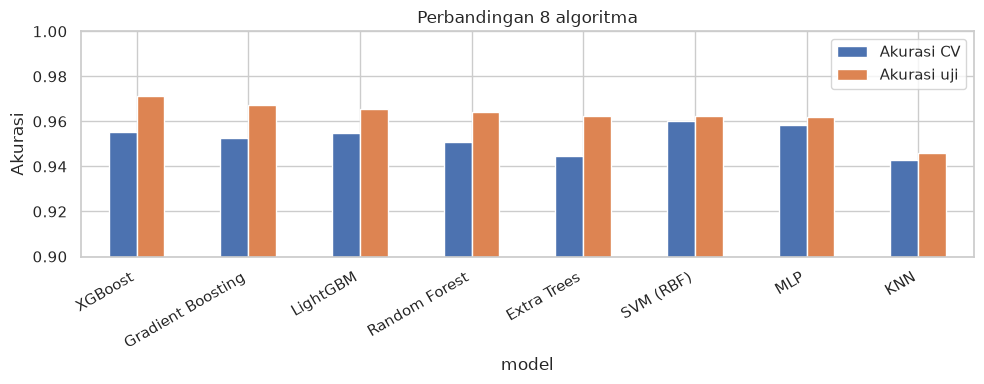

In [23]:
res = pd.read_csv(DATA / "model_results.csv")
display(res.round(4))
best = res.sort_values("accuracy", ascending=False).iloc[0]
bcv = res.sort_values("cv_mean", ascending=False).iloc[0]
print(f"Akurasi uji tertinggi : {best['model']} ({best['accuracy']:.2%}), kappa {best['kappa']:.4f}")
print(f"Akurasi CV tertinggi  : {bcv['model']} ({bcv['cv_mean']:.2%})")
res.set_index("model")[["cv_mean", "accuracy"]].rename(columns={"cv_mean": "Akurasi CV", "accuracy": "Akurasi uji"}) \
   .plot.bar(figsize=(10, 4)); plt.ylim(0.9, 1.0); plt.ylabel("Akurasi"); plt.xticks(rotation=30, ha="right")
plt.title("Perbandingan 8 algoritma"); plt.tight_layout(); plt.show()

In [24]:
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from lightgbm import LGBMClassifier
sc = lambda m: make_pipeline(StandardScaler(), m)
MODELS = {
 "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
 "Extra Trees": ExtraTreesClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
 "SVM (RBF)": sc(SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED)),
 "KNN": sc(KNeighborsClassifier(n_neighbors=7, weights="distance", n_jobs=-1)),
 "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=SEED),
 "XGBoost": XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.9, colsample_bytree=0.9,
                          tree_method="hist", n_jobs=-1, random_state=SEED, eval_metric="mlogloss"),
 "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.1, num_leaves=31, n_jobs=-1, random_state=SEED, verbose=-1),
 "MLP": sc(MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=500, early_stopping=True, random_state=SEED)),
}
fitted, rows = {}, []
if JALANKAN_ULANG_MODEL:
    # label XGBoost harus 0..K-1
    ytr0, yte0 = ytr - 1, yte - 1
    for n, m_ in MODELS.items():
        t0 = time.time(); m_.fit(Xtr, ytr0); p = m_.predict(Xte); fitted[n] = m_
        rows.append({"model": n, "akurasi_ulang": accuracy_score(yte0, p), "kappa_ulang": cohen_kappa_score(yte0, p),
                     "waktu_detik": time.time() - t0})
    rep = pd.DataFrame(rows).merge(res[["model", "accuracy"]].assign(model=lambda d: d.model.str.replace(" (baseline)", "", regex=False)),
                                   on="model", how="left").rename(columns={"accuracy": "akurasi_aplikasi"})
    rep["selisih"] = rep.akurasi_ulang - rep.akurasi_aplikasi
    display(rep.sort_values("akurasi_ulang", ascending=False).round(4))

,model,akurasi_ulang,kappa_ulang,waktu_detik,akurasi_aplikasi,selisih
5,XGBoost,0.9711,0.9652,1.4515,0.9711,0.0000
6,LightGBM,0.9657,0.9587,1.2183,0.9657,-0.0000
4,Gradient Boosting,0.9646,0.9575,23.2615,0.9673,-0.0027
0,Random Forest,0.9641,0.9568,1.7547,0.9641,0.0000
1,Extra Trees,0.9625,0.9549,0.8343,0.9625,0.0000
2,SVM (RBF),0.9625,0.9549,0.1071,0.9625,0.0000
7,MLP,0.9620,0.9542,1.5431,0.9620,0.0000
3,KNN,0.9459,0.9349,0.0619,0.9459,0.0000


**Reproduksi.** Tujuh dari delapan model menghasilkan akurasi uji yang sama persis dengan `model_results.csv`. Gradient Boosting berbeda 0,27 poin (0,9646 vs 0,9673), kemungkinan akibat perbedaan versi scikit-learn; urutan 3 teratas tidak berubah bermakna. Pada 6.3, konfigurasi bawaan (depth 6, lr 0,1) mencapai CV 0,9565 dan yang terbaik (depth 3, lr 0,2) 0,9596; selisih 0,3 poin jauh di bawah simpangan baku (±2,6–3 poin), jadi tuning tidak memberi perbaikan bermakna dan model aplikasi tetap memakai konfigurasi bawaan.

### 6.5 Evaluasi akhir model terbaik (XGBoost)

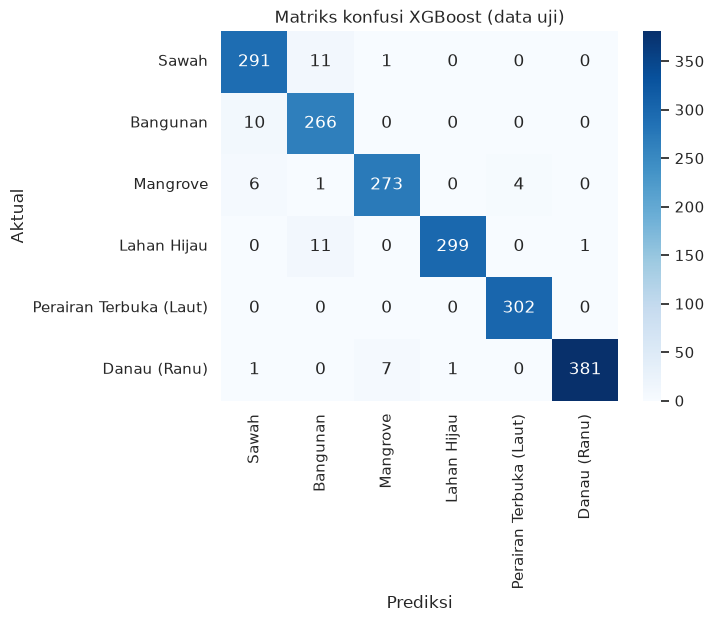

,precision,recall,f1-score,support
Sawah,0.9448,0.9604,0.9525,303.0000
Bangunan,0.9204,0.9638,0.9416,276.0000
Mangrove,0.9715,0.9613,0.9664,284.0000
Lahan Hijau,0.9967,0.9614,0.9787,311.0000
Perairan Terbuka (Laut),0.9869,1.0000,0.9934,302.0000
Danau (Ranu),0.9974,0.9769,0.9870,390.0000
accuracy,0.9711,0.9711,0.9711,0.9711
macro avg,0.9696,0.9706,0.9699,1866.0000
weighted avg,0.9717,0.9711,0.9712,1866.0000


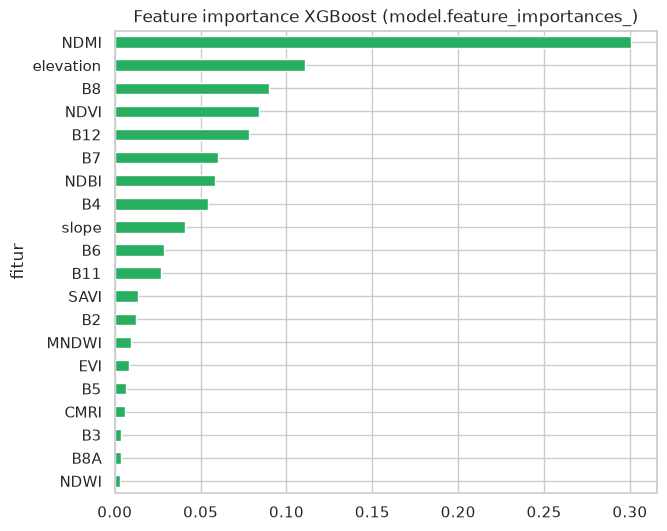

In [25]:
cm = pd.read_csv(DATA / "confusion_matrix.csv", index_col=0)
sns.heatmap(cm.values, annot=True, fmt="d", cmap="Blues", xticklabels=cm.columns, yticklabels=cm.index)
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.title("Matriks konfusi XGBoost (data uji)"); plt.show()
display(pd.read_csv(DATA / "classification_report.csv", index_col=0).round(4))
imp = pd.read_csv(DATA / "feature_importance.csv")
imp.iloc[::-1].plot.barh(x="fitur", y="importance", legend=False, figsize=(7, 6), color="#27ae60")
plt.title("Feature importance XGBoost (model.feature_importances_)"); plt.show()

**Pembacaan.** Kesalahan terbanyak ada pada **Sawah ↔ Bangunan** (11 dan 10 titik) dan **Lahan Hijau → Bangunan** (11 titik): sawah saat bera dan permukiman sama-sama memantulkan SWIR tinggi, dan permukiman desa tercampur pohon. **Danau → Mangrove** (7 titik) terjadi karena keduanya basah dan gelap. Laut paling bersih (recall 1,00). NDMI dan elevasi adalah dua fitur teratas; artinya pemisahan kelas sebagian bersandar pada posisi dataran/pegunungan, bukan hanya spektral. Hal ini berpengaruh pada prediksi di luar daerah sampel (lihat 7.3).

### 6.6 Ukuran data latih

,Porsi data latih,Jumlah titik,Akurasi uji,Std
0,0.10,413,0.9544,0.0054
1,0.25,1032,0.9632,0.0018
2,0.50,2065,0.9659,0.0007
3,0.75,3097,0.9696,0.0005
4,1.00,4130,0.9714,0.0007


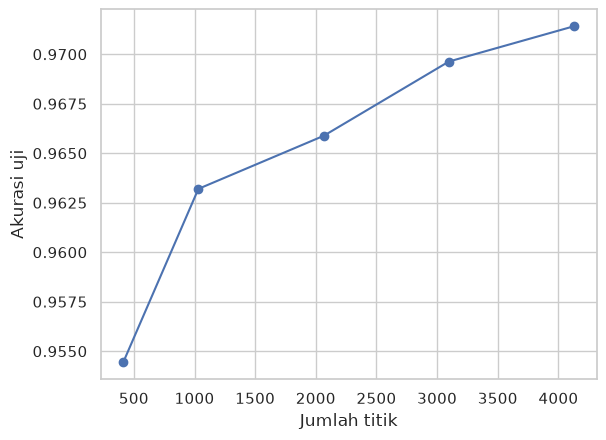

In [26]:
from sklearn.base import clone
xgb = MODELS["XGBoost"]; rows = []
for frac in [0.1, 0.25, 0.5, 0.75, 1.0]:
    accs = []
    for seed in range(3):
        sub = tr.groupby("class_id", group_keys=False).sample(frac=frac, random_state=seed)
        m_ = clone(xgb).fit(sub[FEATURES], sub.class_id - 1)
        accs.append(accuracy_score(yte - 1, m_.predict(Xte)))
    rows.append({"Porsi data latih": frac, "Jumlah titik": int(len(tr) * frac), "Akurasi uji": np.mean(accs), "Std": np.std(accs)})
r66 = pd.DataFrame(rows); display(r66.round(4))
r66.plot(x="Jumlah titik", y="Akurasi uji", marker="o", legend=False); plt.ylabel("Akurasi uji"); plt.show()

## 7. Peta Klasifikasi (XGBoost + Folium + Google Satellite)

### 7.0 Wilayah prediksi
Jawa Timur seluas ±48.000 km² (±480 juta piksel 10 m). Prediksi dilakukan pada 4 ROI yang mewakili keenam kelas, bukan seluruh provinsi. Setiap ROI diekspor dari Earth Engine sebagai GeoTIFF 20-band, diprediksi dengan XGBoost, lalu disimpan sebagai PNG berwarna (`data/roi/*.png`).

In [27]:
roi = json.loads((DATA / "roi_meta.json").read_text())
rows = [{"ROI": v["label"], "Kelas": a["kelas"], "Luas (ha)": a["luas_ha"]} for v in roi.values() for a in v["area"]]
area = pd.DataFrame(rows).pivot(index="Kelas", columns="ROI", values="Luas (ha)").reindex(NAMES).fillna(0)
area["Total"] = area.sum(axis=1)
display(area.round(2))
persen = (area.drop(columns="Total") / area.drop(columns="Total").sum() * 100).round(1)
display(persen.add_suffix(" (%)"))

ROI,Lumajang (Ranu Klakah/Bedali),Malang Selatan (lahan hijau & ranu),Mojokerto - Jombang (sawah),Surabaya - Gresik - Sidoarjo (pesisir),Total
Kelas,,,,,
Sawah,2507.66,507.60,20632.61,3980.08,27627.95
Bangunan,3963.76,2432.73,10520.95,10280.67,27198.11
Mangrove,78.68,6.47,17.04,2400.91,2503.10
Lahan Hijau,24398.75,28155.79,1.19,115.49,52671.22
Perairan Terbuka (Laut),0.00,0.00,0.01,6181.90,6181.91
Danau (Ranu),323.77,135.55,117.19,1011.88,1588.39


ROI,Lumajang (Ranu Klakah/Bedali) (%),Malang Selatan (lahan hijau & ranu) (%),Mojokerto - Jombang (sawah) (%),Surabaya - Gresik - Sidoarjo (pesisir) (%)
Kelas,,,,
Sawah,8.0,1.6,65.9,16.6
Bangunan,12.7,7.8,33.6,42.9
Mangrove,0.3,0.0,0.1,10.0
Lahan Hijau,78.0,90.1,0.0,0.5
Perairan Terbuka (Laut),0.0,0.0,0.0,25.8
Danau (Ranu),1.0,0.4,0.4,4.2


### 7.1 Hasil prediksi per ROI

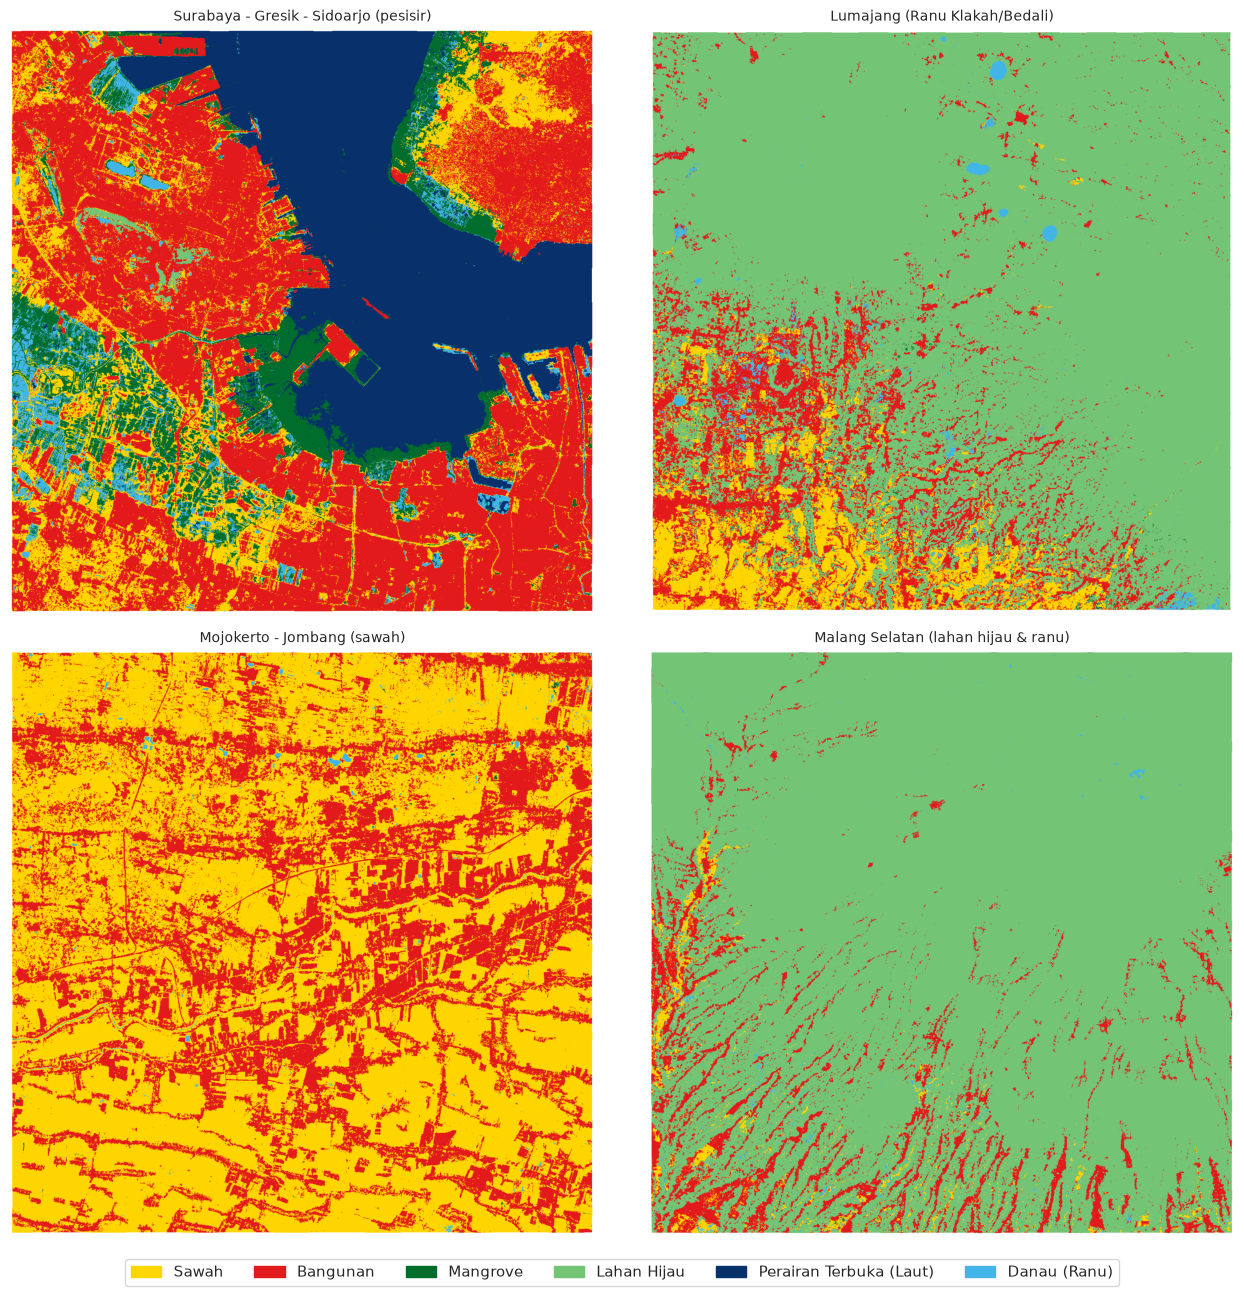

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(13, 13))
for ax, (k, v) in zip(axes.ravel(), roi.items()):
    ax.imshow(mpimg.imread(DATA / "roi" / v["png"])); ax.set_title(v["label"], fontsize=10); ax.axis("off")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=c["color"], label=c["name"]) for c in CLASSES], loc="lower center", ncol=6)
plt.tight_layout(rect=[0, 0.03, 1, 1]); plt.show()

#### 7.1.1 Luas per kelas

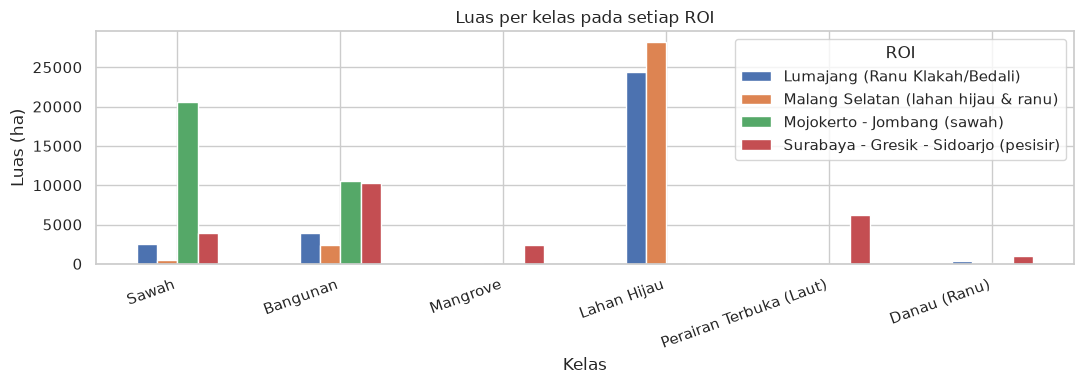

In [29]:
area.drop(columns="Total").plot.bar(figsize=(11, 4)); plt.ylabel("Luas (ha)"); plt.xticks(rotation=20, ha="right")
plt.title("Luas per kelas pada setiap ROI"); plt.tight_layout(); plt.show()

### 7.2 Peta interaktif Folium dengan Google Satellite


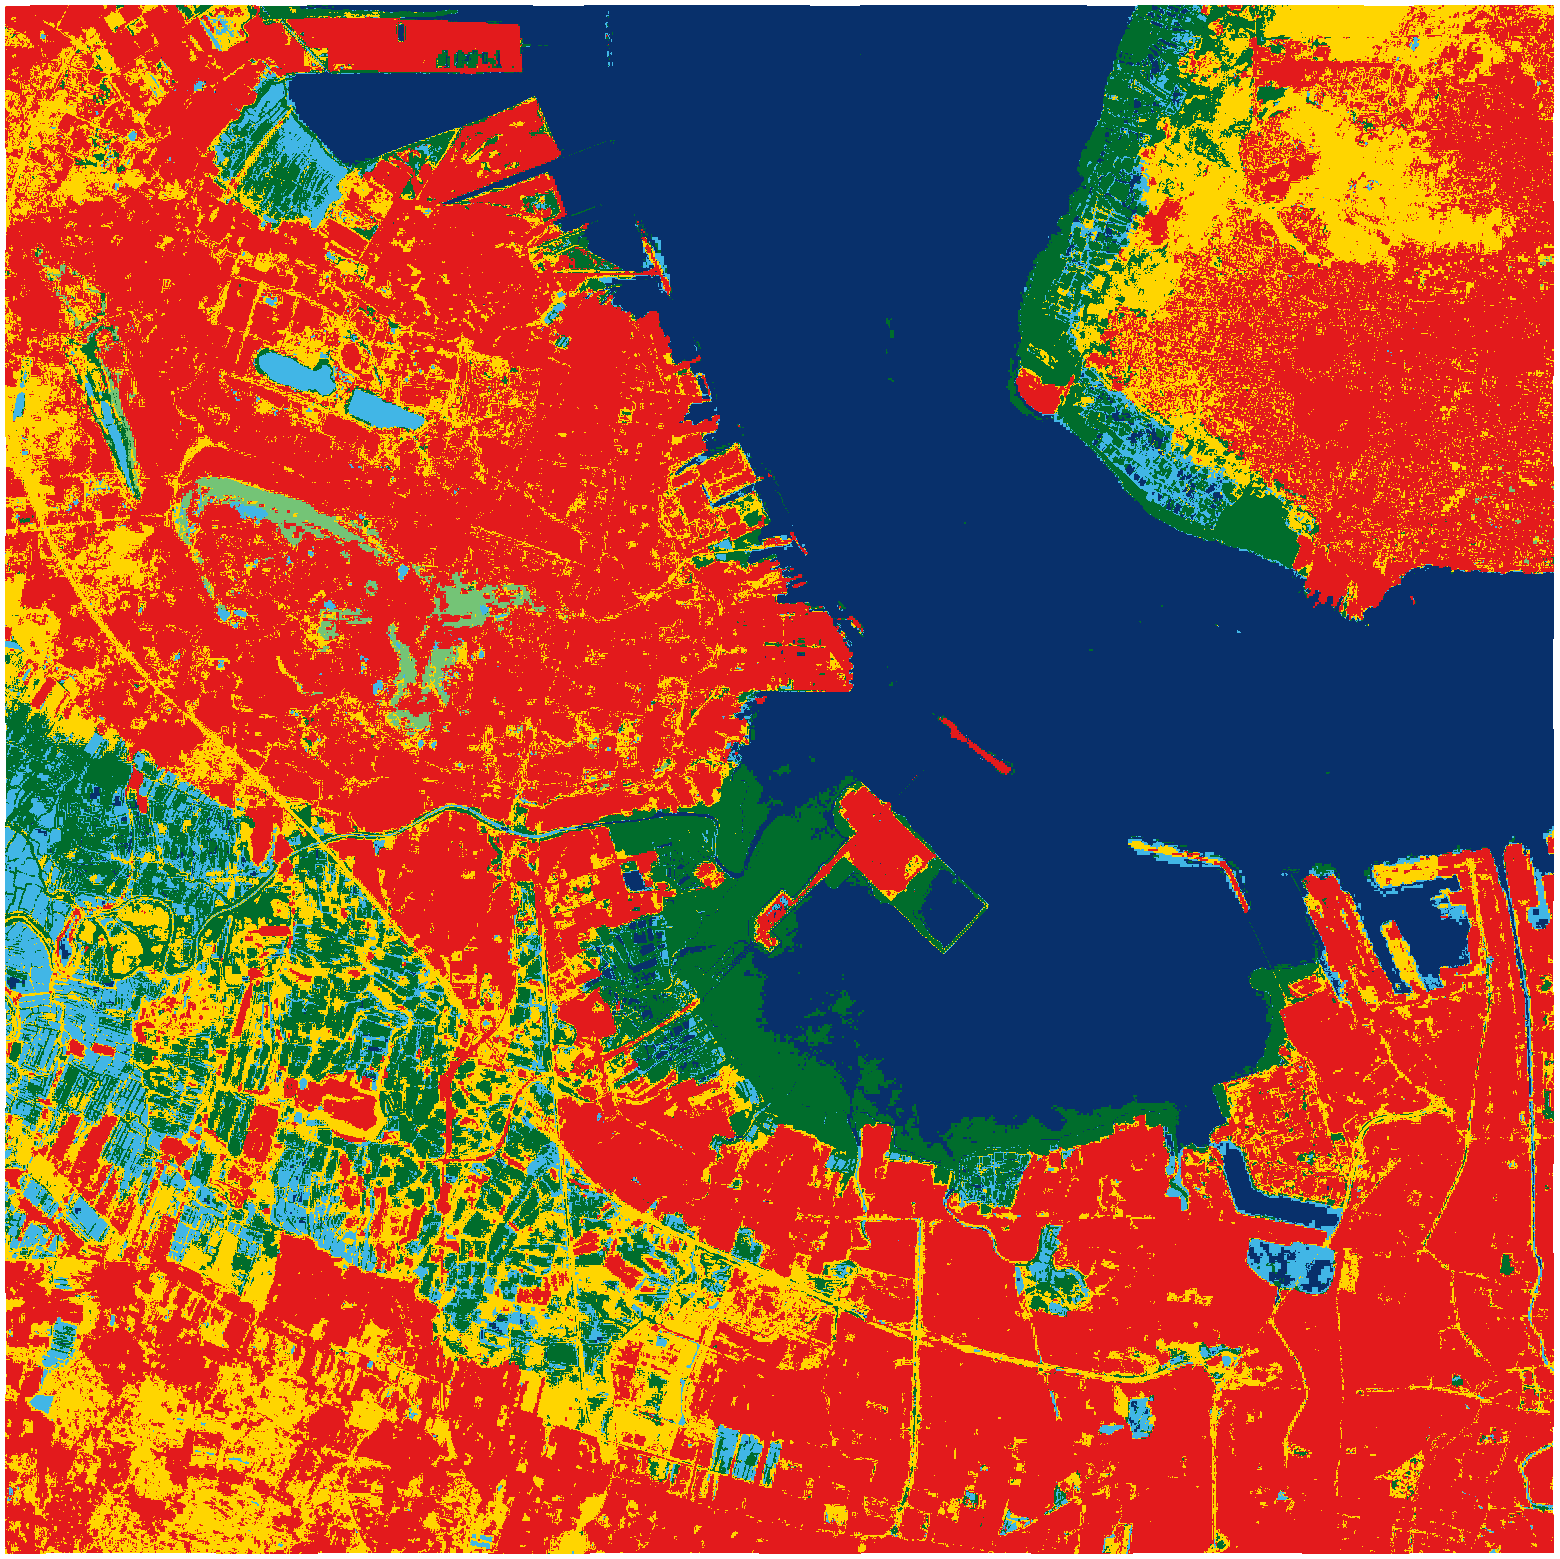
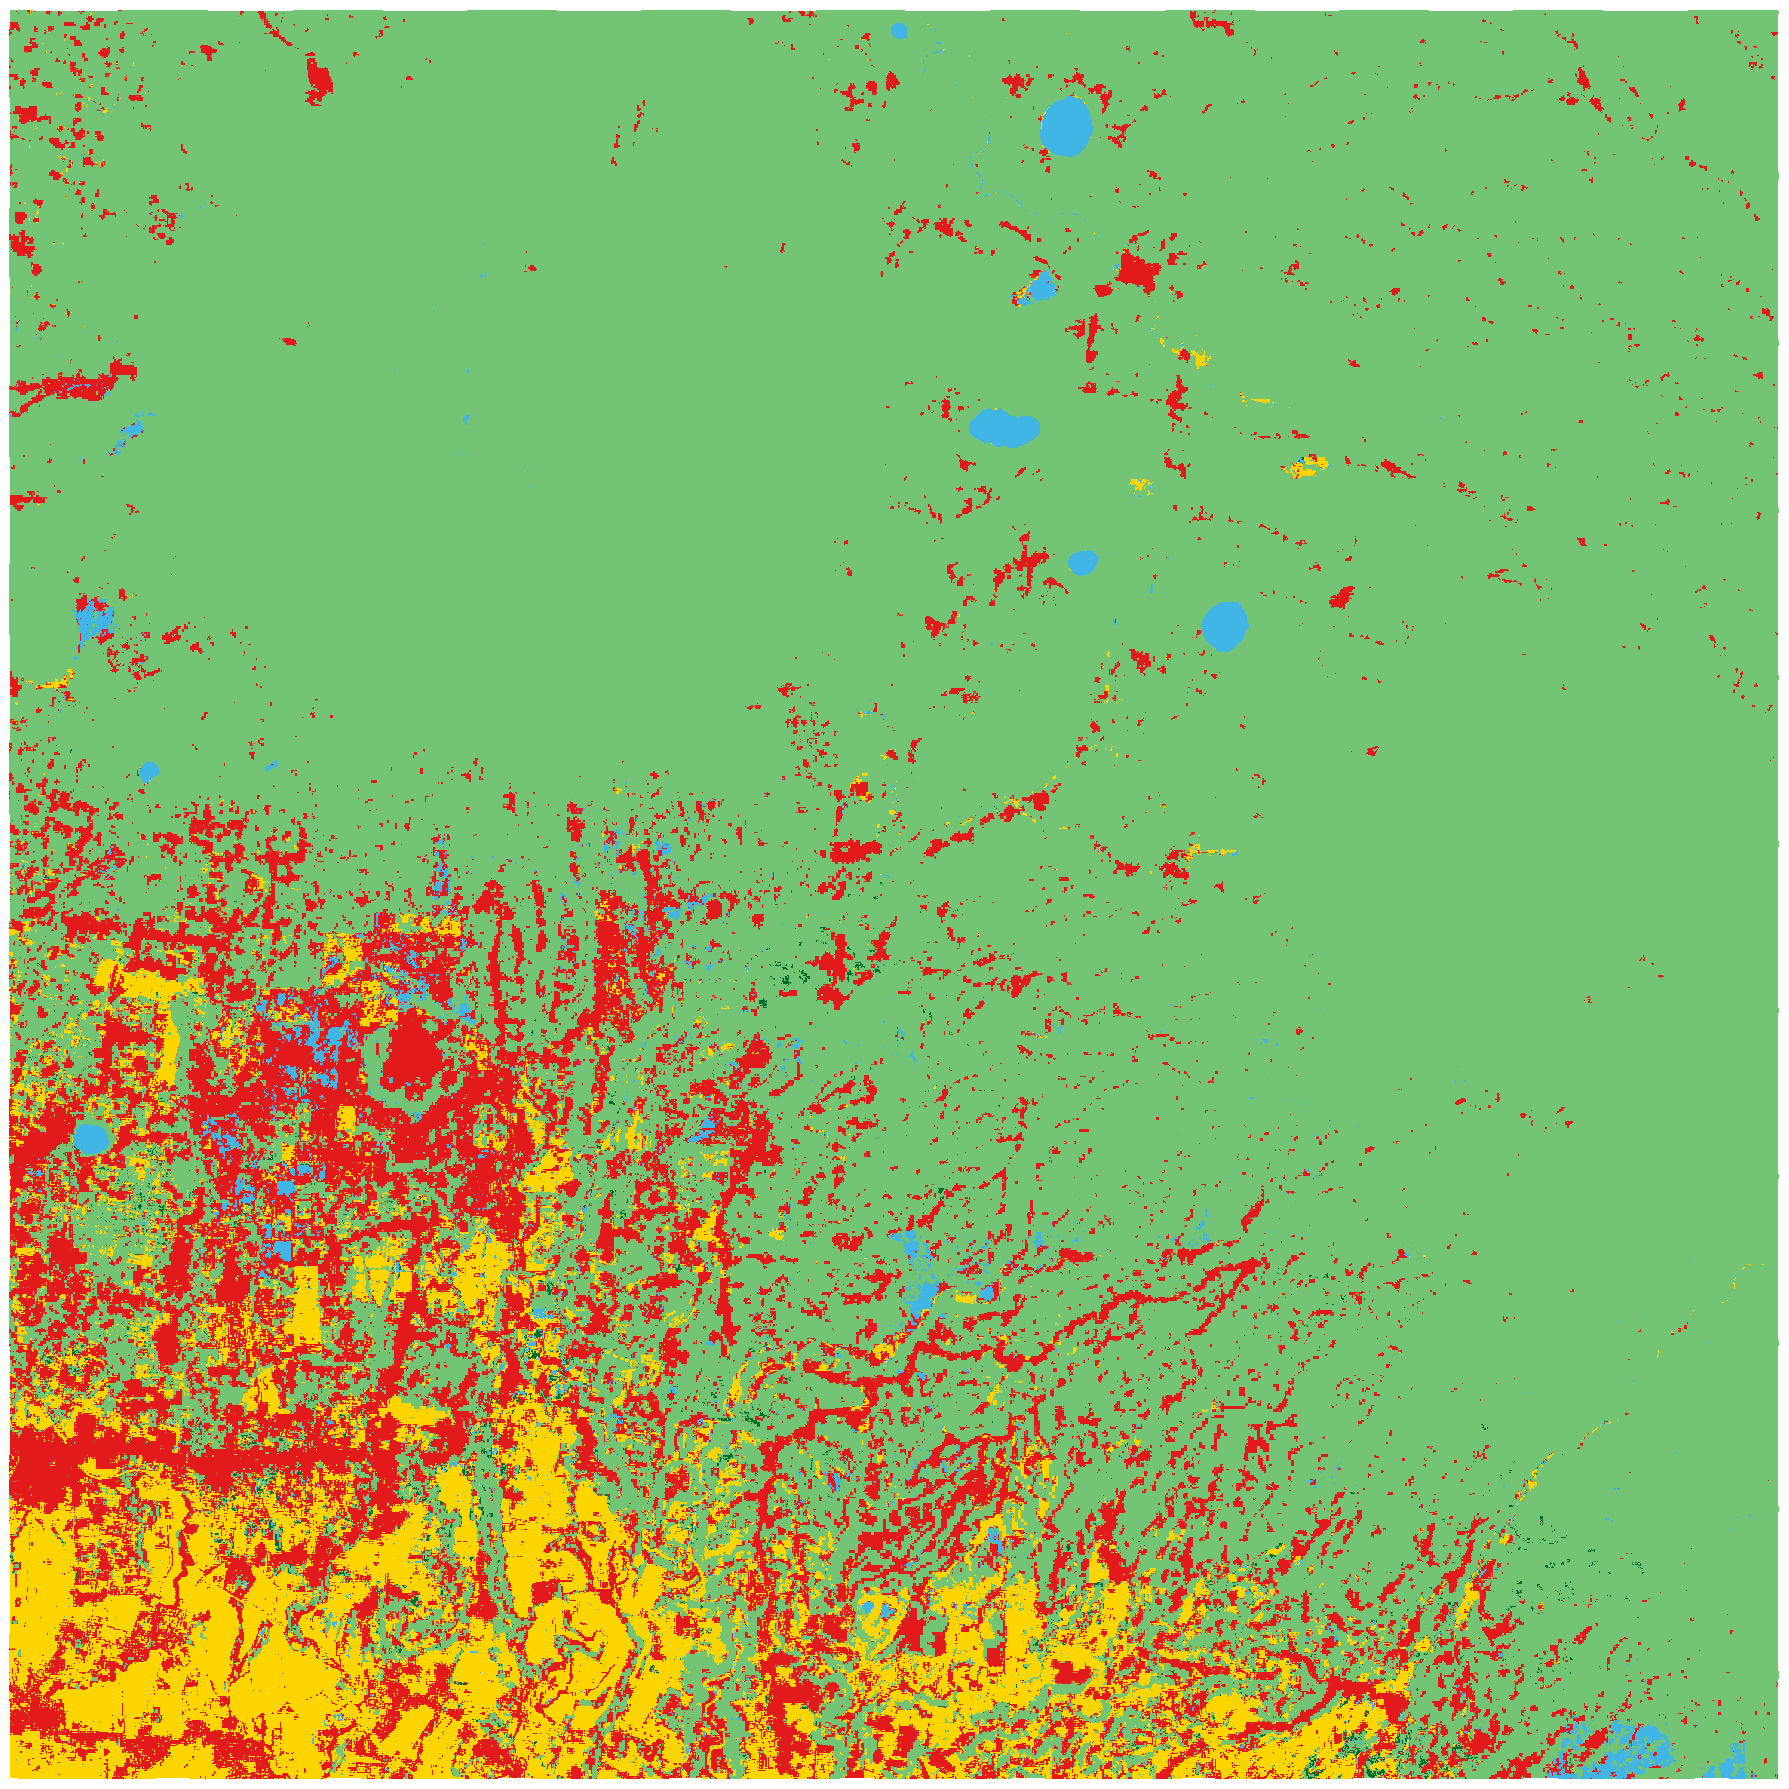
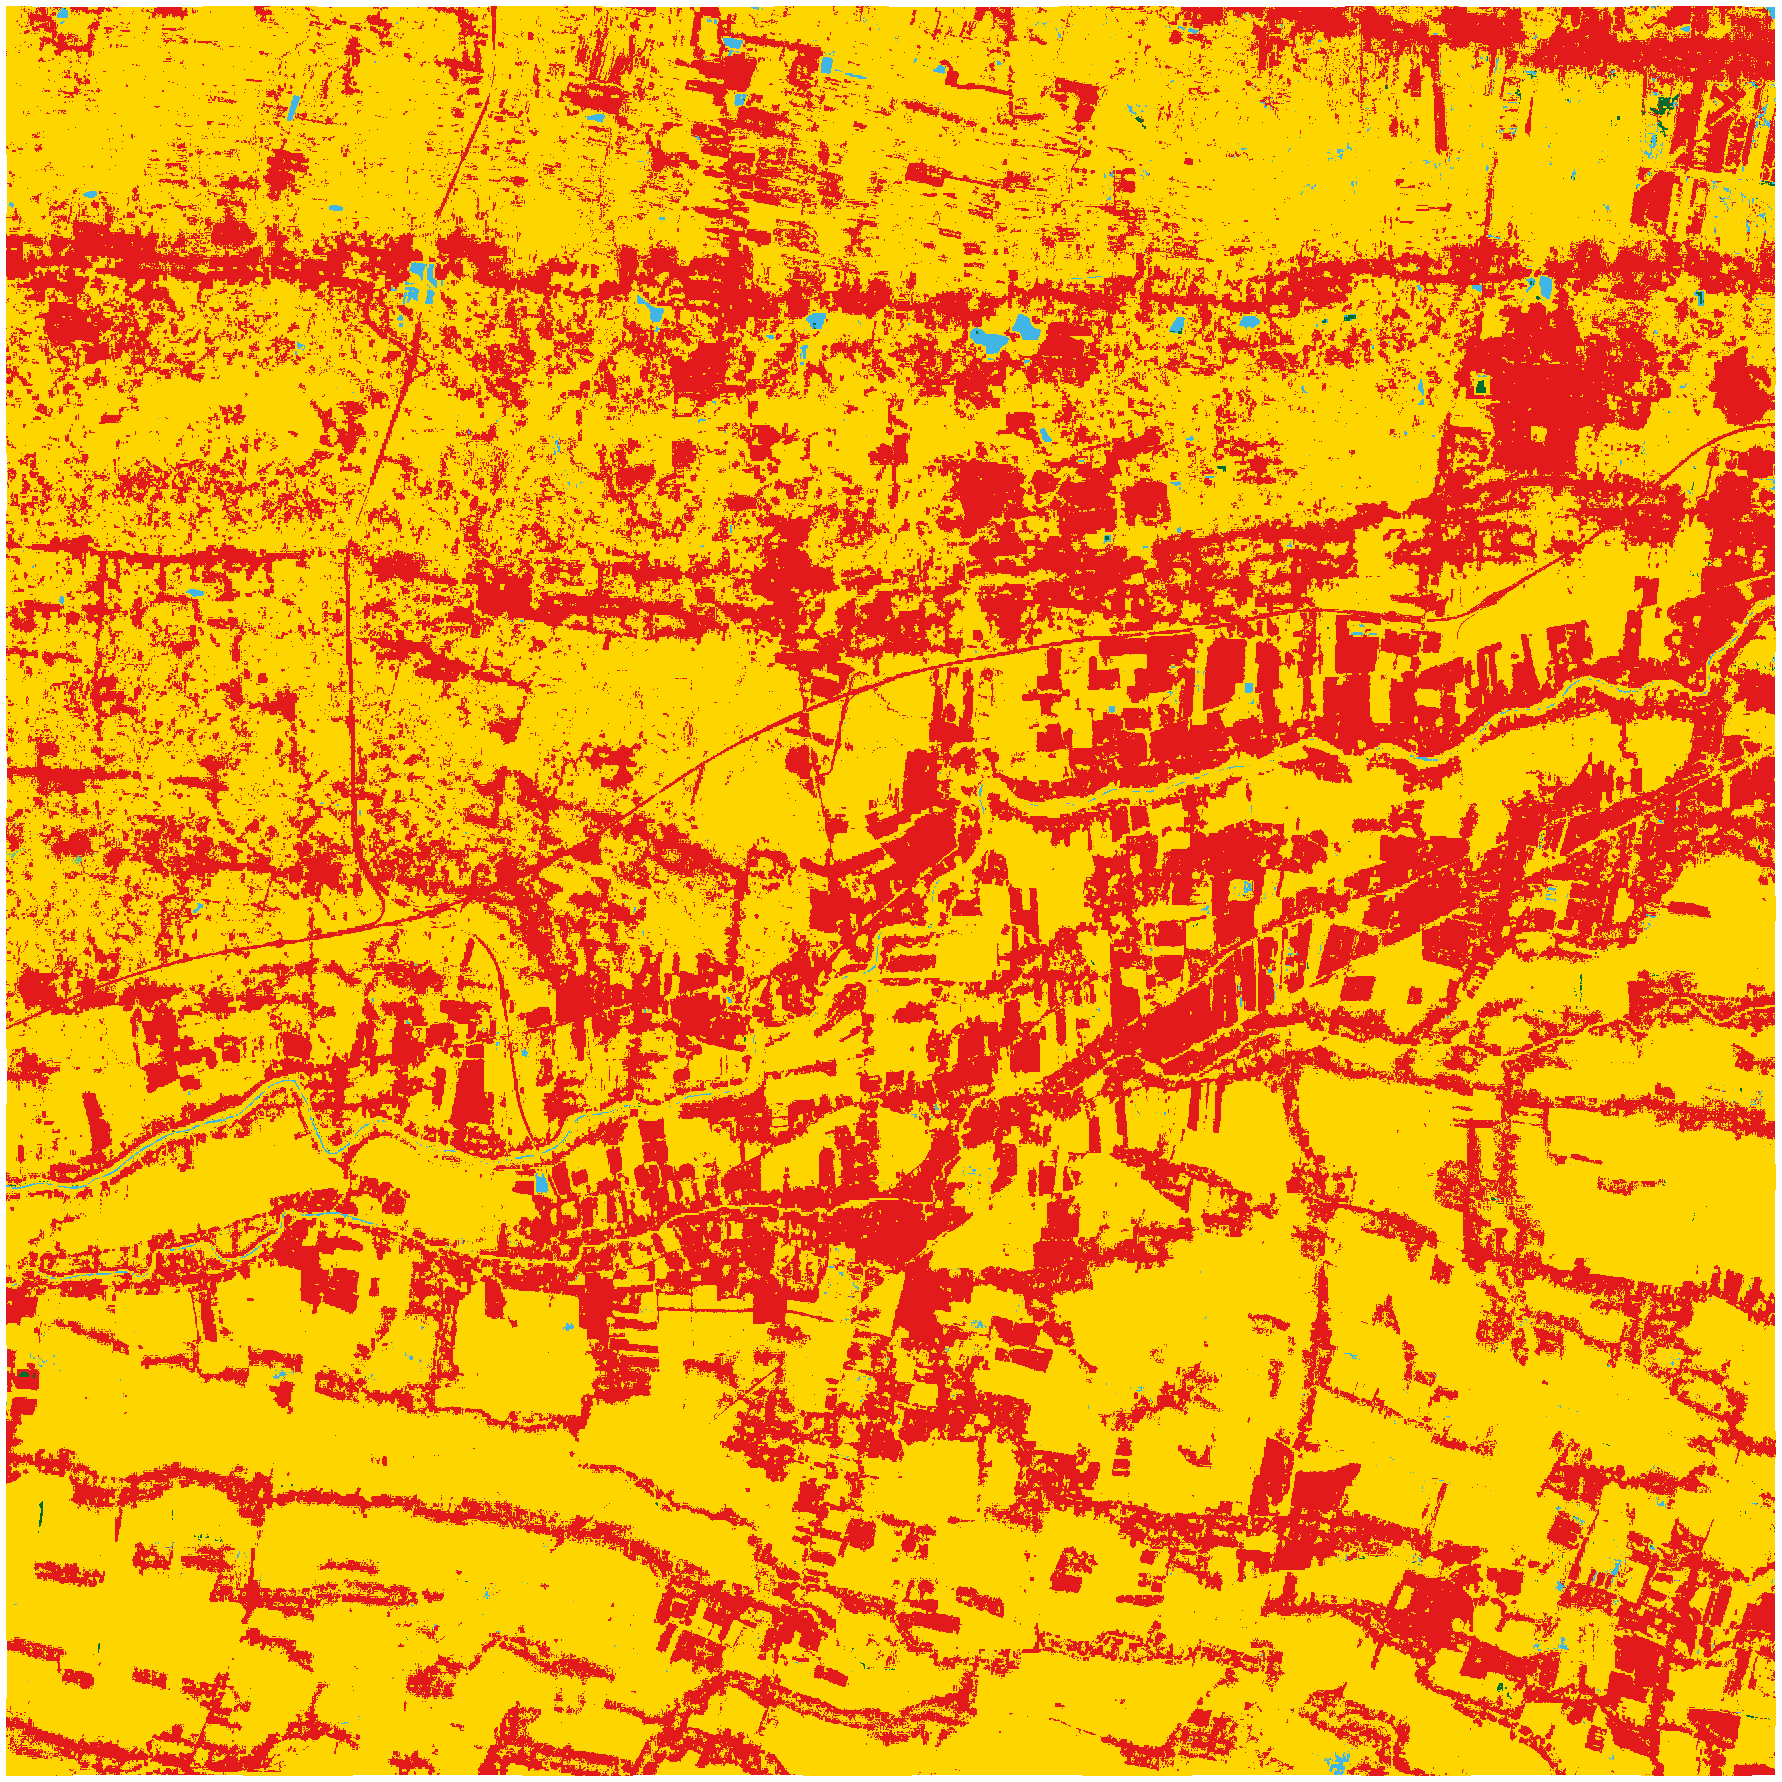
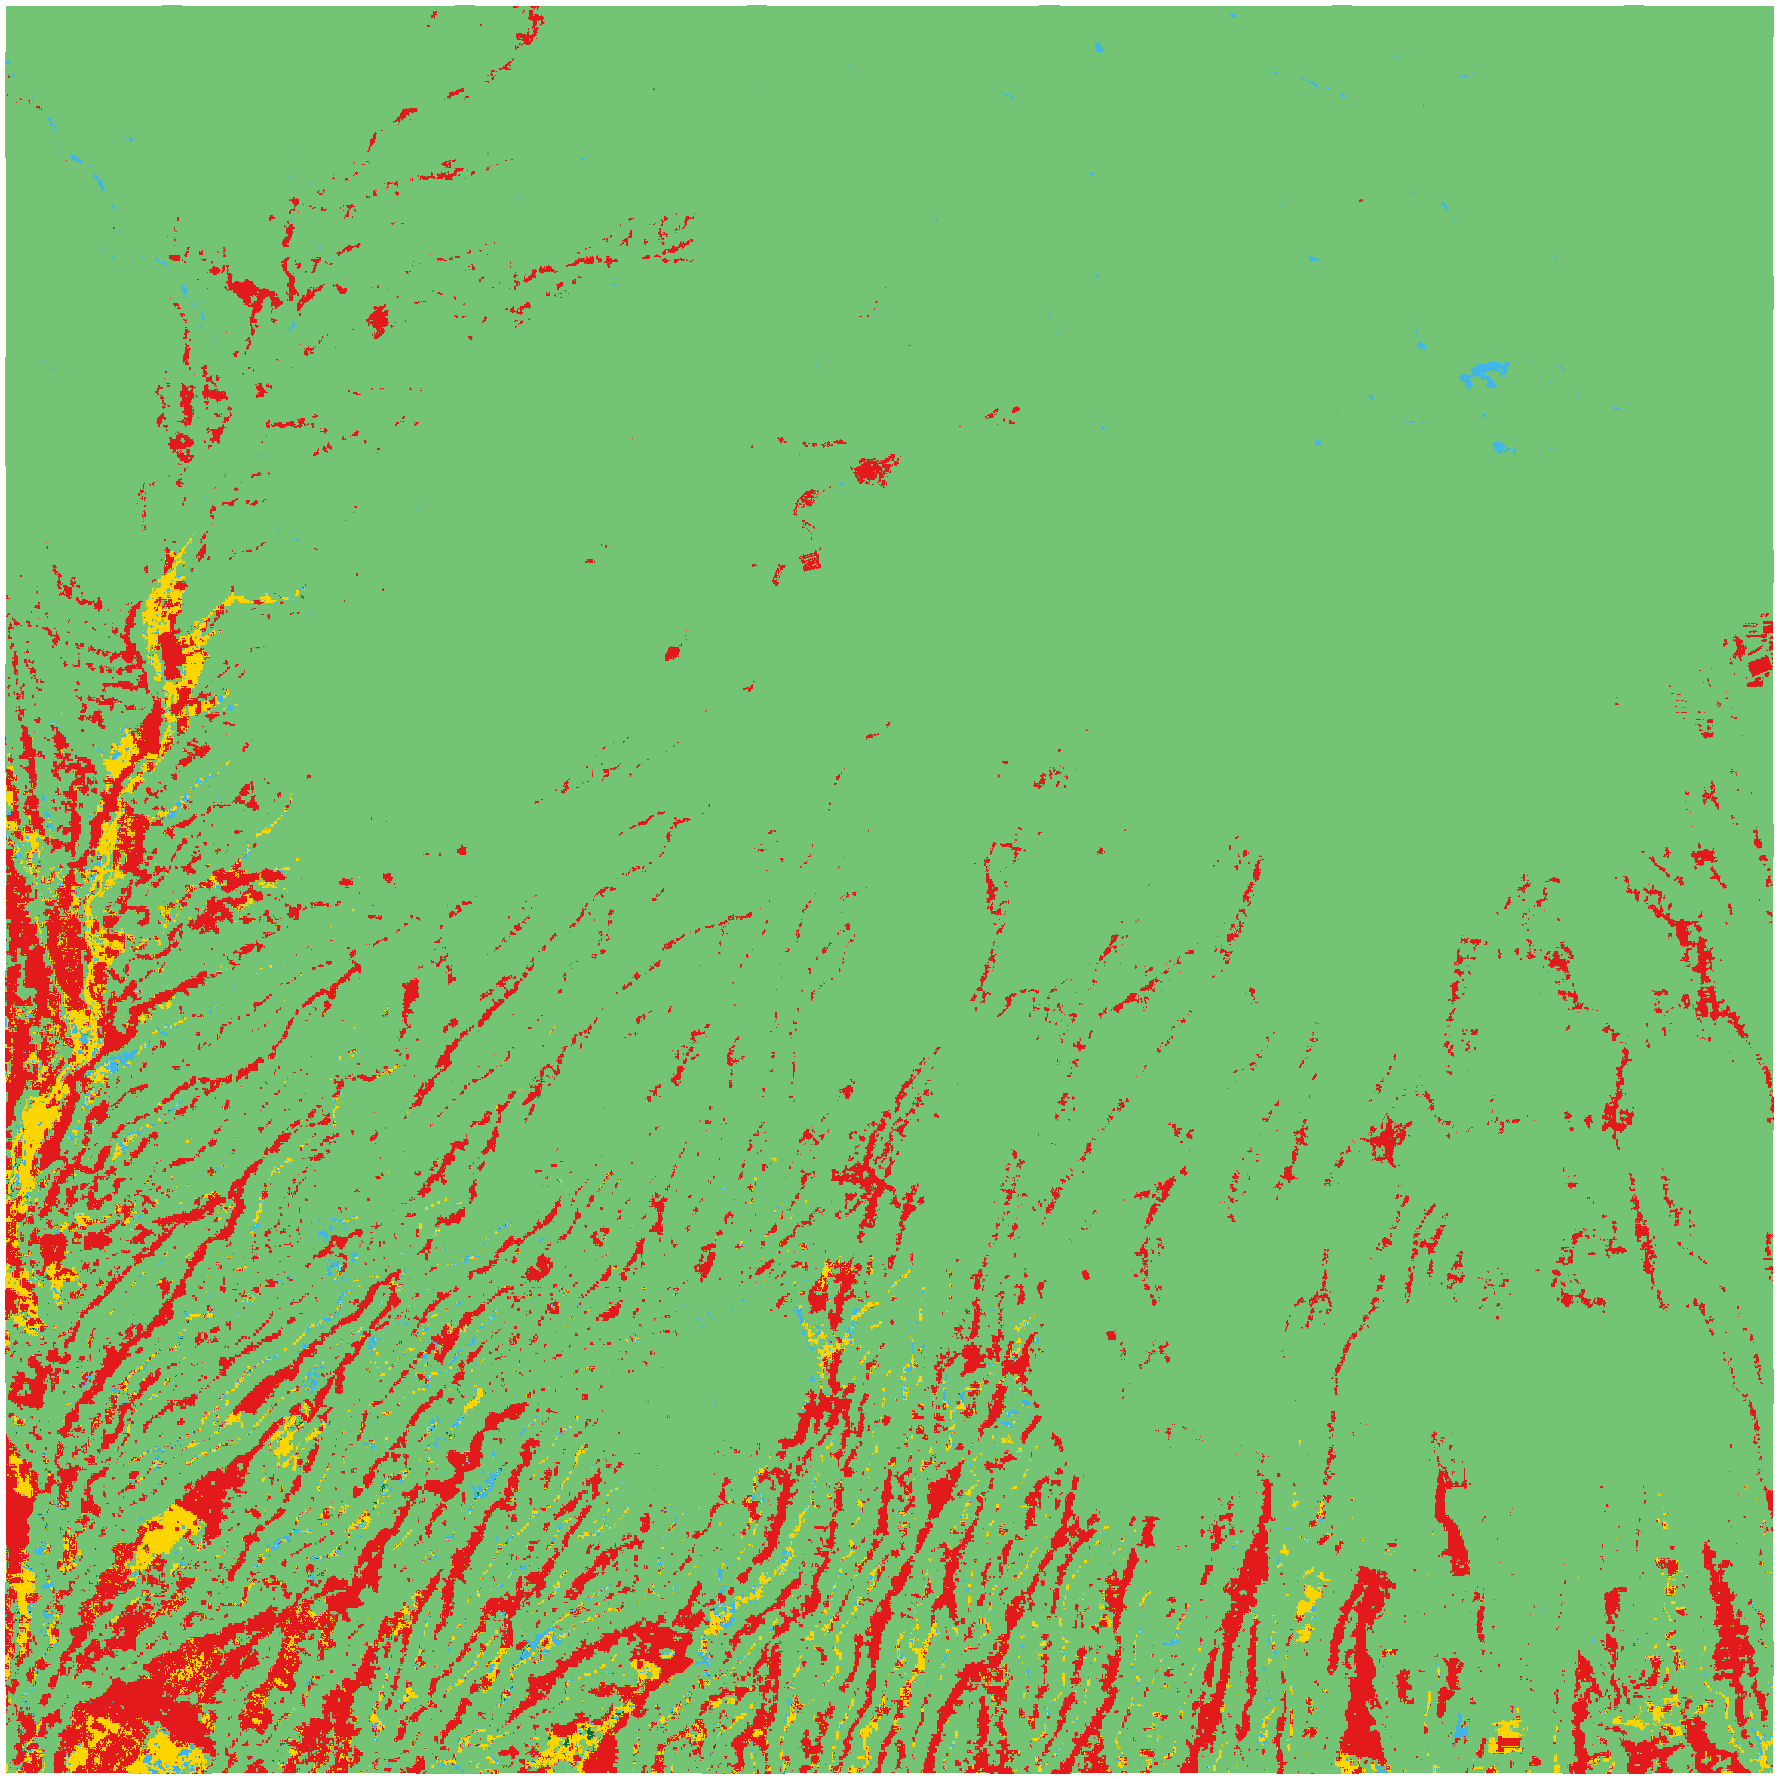

In [30]:
m = folium.Map(location=[-7.75, 112.6], zoom_start=8, tiles=None, control_scale=True)
folium.TileLayer("https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}", name="Google Satellite", attr="Google", max_zoom=20).add_to(m)
folium.TileLayer("https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}", name="Google Hybrid (+label)", attr="Google", max_zoom=20).add_to(m)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(m)
for k, v in roi.items():
    url = "data:image/png;base64," + base64.b64encode((DATA / "roi" / v["png"]).read_bytes()).decode()
    folium.raster_layers.ImageOverlay(image=url, bounds=v["bounds"], opacity=0.7, name=f"Klasifikasi - {v['label']}").add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
legend = "".join(f'<div><span style="background:{c["color"]};width:14px;height:14px;display:inline-block;margin-right:6px;border:1px solid #333"></span>{c["name"]}</div>' for c in CLASSES)
m.get_root().html.add_child(folium.Element('<div style="position:fixed;bottom:24px;left:12px;z-index:9999;background:white;padding:8px 10px;border-radius:6px;box-shadow:0 0 6px rgba(0,0,0,.4);font-size:12px;color:#111"><b>Legenda</b>' + legend + '</div>'))
m.save("peta_klasifikasi.html")
m

### Penjelasan: apa yang dipakai pada peta ini
| Komponen | Yang dipakai | Fungsinya |
|---|---|---|
| Pustaka peta | **Folium** (Python) | Membuat peta **Leaflet** (JavaScript) dari kode Python. Footer peta bertuliskan "Leaflet" karena Folium memakai Leaflet di belakangnya. Jadi ketentuan "Leaflet atau Folium" terpenuhi. |
| Basemap satelit | `folium.TileLayer` dengan URL `https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}` | Menampilkan citra satelit Google Maps. `lyrs=s` artinya satelit, `lyrs=y` artinya hybrid (satelit + label jalan/kota). |
| Hasil klasifikasi | `folium.raster_layers.ImageOverlay` | Menumpuk gambar PNG hasil prediksi XGBoost di atas basemap pada koordinat ROI (`bounds` dari `roi_meta.json`), transparansi 0,7 supaya citra di bawahnya tetap terlihat. |
| Kontrol | `folium.LayerControl` dan legenda HTML | Mengganti basemap, menyalakan/mematikan setiap ROI, dan menjelaskan warna 6 kelas. |

**Catatan istilah WMS.** Google tidak menyediakan layanan WMS resmi. Yang dipakai di sini adalah *tile layer* bergaya XYZ yang diakses langsung oleh Leaflet, yang dalam praktik dipakai sebagai "layer satelit Google Maps". Di laporan, tulis: *"basemap Google Satellite (XYZ tile layer) pada Folium/Leaflet"*. Jika dosen mengharuskan WMS sungguhan, Folium menyediakan `folium.WmsTileLayer(url=..., layers=...)` untuk layanan WMS lain; Google sendiri tidak bisa diakses lewat WMS.

**Alur singkatnya:** model memprediksi kelas tiap piksel → hasilnya disimpan sebagai PNG berwarna → Folium menumpuk PNG itu di atas Google Satellite → disimpan menjadi `peta_klasifikasi.html` yang bisa dibuka di browser mana pun.


Jika peta interaktif tidak tampil (mis. pratinjau GitHub), lihat tangkapan layar halaman Peta Klasifikasi pada 8.1 dan panel statis pada 7.1. Tile Google Satellite memakai URL tidak resmi; basemap Esri World Imagery bisa dipakai sebagai alternatif. Peta ini disimpan juga sebagai `peta_klasifikasi.html` (bisa dibuka tanpa Jupyter).

### 7.3 Implikasi kebijakan dan catatan kualitas hasil
- **Sawah dan alih fungsi lahan.** Di ROI Mojokerto–Jombang, sawah mencakup 20.633 ha (±66%) dan bangunan 10.521 ha (±34%). Perbandingan ini memberi dasar menetapkan Lahan Pertanian Pangan Berkelanjutan (LP2B) di wilayah yang menghimpit permukiman, dan menjadi garis dasar untuk pemantauan tahunan alih fungsi.
- **Mangrove.** Hampir seluruh mangrove ROI berada di Surabaya–Gresik–Sidoarjo (2.401 ha): prioritas perlindungan sempadan pantai dan rehabilitasi, mengingat tekanan tambak dan industri di pesisir tersebut.
- **Danau/ranu.** Luas ranu di ROI Lumajang dan Malang Selatan kecil (324 dan 136 ha) sehingga pemantauan sempadan perlu citra resolusi lebih tinggi.
- **Peringatan kualitas.** ROI Lumajang dan Malang Selatan didominasi lahan hijau, tetapi muncul **bangunan 3.964 ha dan 2.433 ha** di lereng dan hutan; di peta tampak bercak merah di tengah vegetasi. Semua titik latih bangunan berada di dataran rendah (rata-rata elevasi ±89 m), sedangkan lahan hijau di ±1.212 m, sehingga model belajar "dataran tinggi = lahan hijau" dan mengisi piksel di luar pola itu (tanah terbuka, kebun, bayangan lereng) dengan kelas bangunan. Angka bangunan di dua ROI ini **tidak boleh dipakai sebagai dasar kebijakan** tanpa verifikasi lapangan atau penambahan sampel bangunan dan lahan terbuka di dataran tinggi.

## 8. Kesimpulan, Catatan, dan Keterbatasan

In [32]:
b = res.sort_values("accuracy", ascending=False).iloc[0]
print(f"Model terbaik (akurasi uji tertinggi): {b['model']}")
print(f"Akurasi uji {b['accuracy']:.2%} | F1-macro {b['f1_macro']:.4f} | kappa {b['kappa']:.4f} | akurasi CV {b['cv_mean']:.2%} (±{b['cv_std']:.2%})")
print("Fitur terpenting:", ", ".join(imp.fitur.head(5)))

Model terbaik (akurasi uji tertinggi): XGBoost
Akurasi uji 97.11% | F1-macro 0.9699 | kappa 0.9652 | akurasi CV 95.51% (±3.82%)
Fitur terpenting: NDMI, elevation, B8, NDVI, B12


**Kesimpulan**
1. Dari 8 algoritma, **XGBoost** memperoleh akurasi uji tertinggi (97,11%; kappa 0,9652; F1-macro 0,9699), diikuti Gradient Boosting (96,73%) dan LightGBM (96,57%). Selisih antar model ensambel kecil (<1 poin), lebih kecil dari simpangan baku CV (2–4 poin), sehingga keunggulan XGBoost belum tentu bermakna secara statistik. Menurut akurasi CV, SVM (RBF) tertinggi (96,01%).
2. Fitur terpenting: NDMI, elevasi, B8, NDVI, dan B12.
3. Kelas yang paling sering tertukar: sawah dengan bangunan, dan lahan hijau dengan bangunan. Laut paling mudah dikenali.
4. Pemetaan 4 ROI menghasilkan luas per kelas yang konsisten dengan karakter wilayah (sawah di Mojokerto–Jombang, mangrove dan laut di pesisir Surabaya, lahan hijau di lereng), kecuali luas bangunan di dua ROI dataran tinggi (lihat 7.3).

**Keterbatasan**
- Akurasi uji tinggi dihitung pada poligon uji dari area digitasi yang sama; kemampuan generalisasi ke area lain terbukti lebih rendah (kasus bangunan di lereng).
- Kelas bangunan tidak punya sampel di dataran tinggi; kelas "lahan terbuka/kebun" tidak ada sehingga piksel tersebut dipaksa masuk ke salah satu dari 6 kelas.
- Komposit median setahun menghilangkan dinamika musiman sawah.
- Resolusi 10 m: mangrove sempit dan bangunan kecil berupa piksel campuran.
- Poligon digitasi manual, jadi kualitas label menentukan batas atas akurasi.
- Prediksi hanya pada 4 ROI, tidak seluruh provinsi.
- Tile Google Satellite tidak resmi.

**Referensi:** SNI 7645-1:2014; klasifikasi penutupan lahan KLHK; Drusch et al. (2012) Sentinel-2; Google Earth Engine Data Catalog `COPERNICUS/S2_SR_HARMONIZED`; Chen & Guestrin (2016) XGBoost.